# EDA · Detección de transacciones bancarias fraudulentas

**Documento de referencia de las decisiones del proyecto.** Cada decisión técnica de la práctica (deduplicar, métrica, validación, tipo de modelo, regularización, transformaciones, ensemble, uso de producción) se apoya en un hallazgo de este análisis. La sección 12 reúne el mapa *hallazgo → decisión* con las cifras calculadas en esta misma ejecución.

**Principios del análisis**
- Es **descriptivo**: no ajusta ningún modelo predictivo. Las únicas piezas "de modelo" (Mahalanobis, PCA, k-means, validación adversaria) se usan como *instrumentos de medida* y se señalan como tales.
- Las etiquetas (`Class`) se usan para **describir** diferencias entre clases, nunca para tomar decisiones sobre datos de validación o producción.
- Las conclusiones que contradicen una expectativa previa se dicen explícitamente.

**Datos.** `credit_card_construction.csv` (etiquetado) y `credit_card_production.csv` (sin etiqueta; es el que se puntúa). Se buscan en `./`, `./data/` y `../data/`.

**Versión 2 (Fase 5).** Respecto a la v1: figuras corregidas (el recorte de rango de la v1 sugería un "amontonamiento en el borde" que era un artefacto del gráfico), análisis nuevos (firma de cola, orden de filas, subgrupos de fraude con prueba de estabilidad, frecuencia de importes, intervalos de confianza del AUC, dependencia no lineal) y una **verificación automática** de cada cifra citada en el texto (sección 12b).

**Hallazgos clave** (todos verificados en la sección 12b)
1. Fraude: 0,17 % de las filas (285 únicos tras deduplicar). Hay que deduplicar (4 167 copias sobrantes) y usar AUPR con particiones estratificadas.
2. **Firma de cola:** el fraude es extremo, en el mismo sentido y en muchas variables a la vez; una decena de variables concentra ≥ 30 % de los fraudes más allá de los percentiles 0,2/99,8.
3. **Dos subpoblaciones de fraude estables:** una *fuerte* (~3/4) y una *suave* (~1/4), distinguidas por intensidad.
4. Las X son **linealmente incorrelacionadas pero dependientes** (no lineal); la transformación `arcsinh` es crítica para modelos de una gaussiana y neutra para árboles.
5. `Amount`: señal discreta (valores exactos recurrentes y `Amount = 0`), no monótona.
6. Producción y construcción son indistinguibles (AUC adversaria ≈ 0,50); el orden de filas no contiene información.
7. La métrica tiene un ruido de ≈ 0,06 por muestreo: diferencias de milésimas no son significativas.

**Índice.** 1 Estructura · 2 Calidad (y orden de filas) · 3 Variable objetivo · 4 Distribuciones · 5 Relación con el fraude (firma de cola, importes) · 6 Correlaciones · 7 Colas y valores atípicos · 8 Estructura multivariante · 9 Heterogeneidad del fraude · 10 Construcción vs producción · 11 Ruido de la métrica · 12 Mapa de decisiones y verificación · 13 Limitaciones e hipótesis

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, silhouette_score

warnings.filterwarnings("ignore")
SEED = 42
AZUL, ROJO, GRIS = "#4C78A8", "#D1495B", "#8A8F98"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = None


def localizar(nombre):
    """Busca el CSV en ./, ./data y ../data."""
    for carpeta in (".", "data", "../data"):
        ruta = Path(carpeta) / nombre
        if ruta.exists():
            return ruta
    raise FileNotFoundError(f"No se encuentra {nombre}: colócalo en ./data/")


tr = pd.read_csv(localizar("credit_card_construction.csv"))
pr = pd.read_csv(localizar("credit_card_production.csv"))
OBJ, IMP = "Class", "Amount"
XS = [c for c in tr.columns if c.startswith("X")]
y = tr[OBJ].to_numpy(int)
F, N = tr[tr[OBJ] == 1], tr[tr[OBJ] == 0]
asinh = lambda v: np.arcsinh(np.asarray(v, float) / 100.0)  # misma transformación del proyecto
print(f"construcción {tr.shape} · producción {pr.shape} · variables X: {len(XS)}")

construcción (170884, 22) · producción (113923, 22) · variables X: 20


## 1. Estructura de los datos

**Pregunta.** ¿Qué tipo de datos son y qué columnas tenemos? Determina si hay que codificar categóricas, tratar fechas o imputar.

In [2]:
info = pd.DataFrame({
    "dtype": tr.dtypes.astype(str),
    "únicos": tr.nunique(),
    "min": tr.min(), "mediana": tr.median(), "max": tr.max(),
})
display(info)
print(f"Memoria construcción: {tr.memory_usage().sum() / 1e6:.1f} MB · producción: {pr.memory_usage().sum() / 1e6:.1f} MB")
print("Columnas idénticas en ambos ficheros:", list(tr.columns) == list(pr.columns))
print("Columna objetivo en producción: nulos =", int(pr[OBJ].isna().sum()), "de", len(pr))

,dtype,únicos,min,mediana,max
X1,float64,1646,"-11,282.0000",4.0000,490.0000
X2,float64,2145,"-14,544.0000",14.0000,"4,294.0000"
X3,float64,1374,"-6,594.0000",36.0000,"1,876.0000"
X4,float64,1219,"-1,136.0000",-4.0000,"3,344.0000"
X5,float64,1733,"-6,418.0000",-12.0000,"6,960.0000"
X6,float64,1393,"-5,232.0000",-54.0000,"4,278.0000"
X7,float64,1723,"-8,302.0000",8.0000,"6,860.0000"
X8,float64,1859,"-14,644.0000",4.0000,"4,002.0000"
X9,float64,1144,"-2,686.0000",-10.0000,"3,118.0000"
X10,float64,1547,"-4,880.0000",-18.0000,"4,750.0000"


Memoria construcción: 30.1 MB · producción: 20.1 MB
Columnas idénticas en ambos ficheros: True
Columna objetivo en producción: nulos = 113923 de 113923


**Lectura.**
- 21 variables numéricas (`X1..X20` y el importe `Amount`) más la etiqueta. **No hay categóricas, fechas, identificadores de cuenta ni de comercio.**
- Consecuencias: (i) no hace falta codificación; (ii) **no es posible una validación temporal** (no hay tiempo) ni variables de comportamiento (frecuencia o recencia por cuenta), que la spec planteaba como posibles; (iii) los datos caben en memoria (~30 MB), así que no hay restricción de volumen.
- `Class` está vacía en producción: es el hueco que rellenamos con nuestro score.

## 2. Calidad de los datos

**Preguntas.** ¿Hay nulos, duplicados o valores sentinela? ¿Cómo se han generado/redondeado los valores? Una mala calidad invalida la validación aunque el modelo sea bueno.

In [3]:
print("Nulos construcción:", int(tr.isna().sum().sum()), "· nulos producción (sin objetivo):", int(pr.drop(columns=OBJ).isna().sum().sum()))
print("Infinitos:", int(np.isinf(tr[XS + [IMP]].to_numpy()).sum()))

dup_todas = tr.duplicated(keep=False)          # todas las filas pertenecientes a un grupo repetido
dup_extra = tr.duplicated(keep="first")        # copias sobrantes (lo que elimina deduplicar)
multiplicidad = tr.groupby(list(tr.columns)).size()
resumen = pd.DataFrame({
    "filas": [len(tr), int(dup_todas.sum()), int(dup_extra.sum()), len(tr) - int(dup_extra.sum())],
    "fraudes": [int(y.sum()), int(tr.loc[dup_todas, OBJ].sum()), int(tr.loc[dup_extra, OBJ].sum()),
                int(tr.loc[~dup_extra, OBJ].sum())],
}, index=["total", "en grupos repetidos", "copias sobrantes", "tras deduplicar"])
resumen["% del total"] = 100 * resumen["filas"] / len(tr)
display(resumen)
print(f"Tasa de filas en grupos repetidos: normales {dup_todas[tr[OBJ] == 0].mean():.2%} · fraudes {dup_todas[tr[OBJ] == 1].mean():.2%}")
print("Máxima multiplicidad de una misma fila:", int(multiplicidad.max()))
print("Grupos repetidos por tamaño:", multiplicidad[multiplicidad > 1].value_counts().sort_index().head(6).to_dict())
print("¿Alguna fila idéntica con etiquetas distintas?", bool(tr.drop(columns=OBJ).duplicated(keep=False).sum() - dup_todas.sum()))
print(f"Producción: {pr.drop(columns=OBJ).duplicated().sum()} filas duplicadas ({pr.drop(columns=OBJ).duplicated().mean():.2%})")

Nulos construcción: 0 · nulos producción (sin objetivo): 0
Infinitos: 0


,filas,fraudes,% del total
total,170884,295,100.0000
en grupos repetidos,6603,16,3.8640
copias sobrantes,4167,10,2.4385
tras deduplicar,166717,285,97.5615


Tasa de filas en grupos repetidos: normales 3.86% · fraudes 5.42%
Máxima multiplicidad de una misma fila: 49
Grupos repetidos por tamaño: {2: 1822, 3: 363, 4: 100, 5: 45, 6: 24, 7: 17}


¿Alguna fila idéntica con etiquetas distintas? False


Producción: 2109 filas duplicadas (1.85%)


In [4]:
v = tr[XS].to_numpy()
print("X: todos los valores enteros:", bool(np.allclose(v, np.round(v))), "· todos pares:", bool(np.allclose(np.mod(np.round(v), 2), 0)))
print("X: valores distintos por variable (mín-máx):", tr[XS].nunique().min(), "-", tr[XS].nunique().max())
print(f"Amount con más de 2 decimales: {((tr[IMP] * 100 - np.round(tr[IMP] * 100)).abs() > 1e-6).mean():.2%} · con céntimos: {((tr[IMP] % 1) > 1e-9).mean():.2%}")

cero = pd.crosstab(tr[OBJ], tr[IMP] == 0)
cero.columns = ["Amount > 0", "Amount = 0"]
display(cero)
p_cero = stats.fisher_exact(cero.to_numpy())[1]
tasa0, tasa1 = (N[IMP] == 0).mean(), (F[IMP] == 0).mean()
print(f"Amount = 0: normales {tasa0:.2%} · fraudes {tasa1:.2%} → {tasa1 / tasa0:.1f} veces más frecuente en fraude (Fisher p = {p_cero:.1e})")

X: todos los valores enteros: True · todos pares: True


X: valores distintos por variable (mín-máx): 728 - 2145
Amount con más de 2 decimales: 0.00% · con céntimos: 87.75%


,Amount > 0,Amount = 0
Class,,
0,169518,1071
1,283,12


Amount = 0: normales 0.63% · fraudes 4.07% → 6.5 veces más frecuente en fraude (Fisher p = 5.6e-07)


**Lectura.**
- **Sin nulos ni infinitos.** No hace falta imputar.
- **Duplicados reales y numerosos** (~2,4 % de copias sobrantes, ~3,9 % de filas dentro de un grupo repetido), con grupos de hasta decenas de copias. No hay filas idénticas con etiquetas contradictorias. Si un mismo registro cae en el pliegue de ajuste y en el de validación, **la validación se infla** (el modelo "reconoce" la fila). **→ Decisión: deduplicar antes de partir** (tras ello: 166 717 filas, 285 fraudes).
- Las variables `X` son **enteros pares** (rejilla de paso 2): han sido escaladas y redondeadas. Con ~700-2 100 valores distintos por variable son prácticamente continuas, pero conviene saber que **no son magnitudes físicas** y que los árboles verán muchos empates.
- **`Amount = 0` es mucho más frecuente en fraude** (~6,5 veces). Es una señal discreta que un modelo de árboles captura de forma natural y una transformación logarítmica aplastaría (log1p(0) = 0 se confunde con importes minúsculos).

In [5]:
# ¿Importa el orden de las filas? Si los fraudes se agrupasen por posición, el índice sería una variable "oculta".
pos = np.flatnonzero(y == 1) / len(tr)
p_orden = stats.kstest(pos, "uniform").pvalue
consec = int((np.diff(np.flatnonzero(y == 1)) == 1).sum())
print(f"Posición relativa de los fraudes en el fichero: KS frente a uniforme p = {p_orden:.2f} · fraudes por cuartil del fichero: {np.histogram(pos, bins=4, range=(0, 1))[0].tolist()}")
print(f"Pares de fraudes en filas consecutivas: {consec} · autocorrelación lag-1: Class {tr[OBJ].autocorr(1):.3f}, Amount {tr[IMP].autocorr(1):.3f}, X1 {tr['X1'].autocorr(1):.3f}")

Posición relativa de los fraudes en el fichero: KS frente a uniforme p = 0.84 · fraudes por cuartil del fichero: [67, 83, 70, 75]
Pares de fraudes en filas consecutivas: 1 · autocorrelación lag-1: Class 0.002, Amount -0.004, X1 -0.002


**Lectura.** El **orden de las filas no contiene información**: los fraudes están repartidos uniformemente por el fichero (no se rechaza la uniformidad), casi no hay fraudes contiguos y no hay autocorrelación. **→ Consecuencias:** (i) no hay una variable "posición" oculta que explotar ni que deba protegerse; (ii) el único requisito de orden es práctico: el CSV de entrega debe respetar el orden del fichero de producción.

## 3. Variable objetivo y desbalanceo

**Pregunta.** ¿Cuán raro es el fraude y qué implica para la métrica y la validación?

original    : 295 fraudes de 170884 = 0.1726%  (IC95 % 0.1540% – 0.1935%) · 1 de cada 579
deduplicado : 285 fraudes de 166717 = 0.1709%  (IC95 % 0.1522% – 0.1920%) · 1 de cada 585

AUPR de un clasificador aleatorio = prevalencia = 0.0017  (el ensemble final ronda 0,83: ~486 veces mejor)
Fraudes por pliegue de validación con K=5: ~57
Fraudes por pliegue de validación con K=10: ~28
Accuracy de predecir siempre 'no fraude': 99.8291%


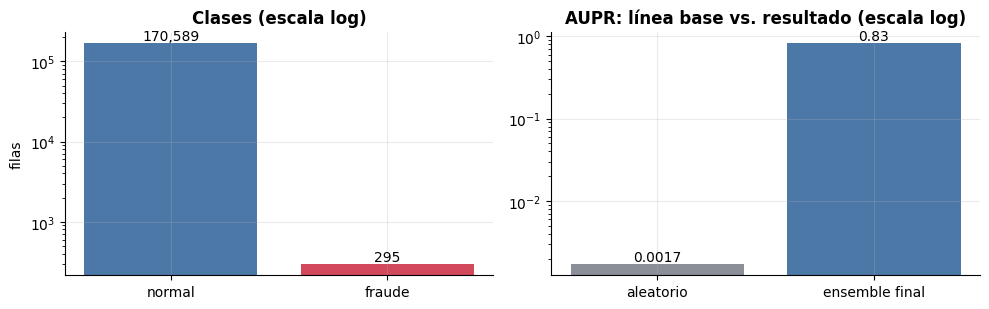

In [6]:
def wilson(k, n, z=1.96):
    """Intervalo de Wilson al 95 % para una proporción."""
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


dd = tr.drop_duplicates()
for nombre, d in (("original", tr), ("deduplicado", dd)):
    k, n = int(d[OBJ].sum()), len(d)
    lo, hi = wilson(k, n)
    print(f"{nombre:12s}: {k} fraudes de {n} = {k / n:.4%}  (IC95 % {lo:.4%} – {hi:.4%}) · 1 de cada {n / k:,.0f}")

prev = dd[OBJ].mean()
print(f"\nAUPR de un clasificador aleatorio = prevalencia = {prev:.4f}  (el ensemble final ronda 0,83: ~{0.83 / prev:,.0f} veces mejor)")
for k_folds in (5, 10):
    print(f"Fraudes por pliegue de validación con K={k_folds}: ~{dd[OBJ].sum() / k_folds:.0f}")
print(f"Accuracy de predecir siempre 'no fraude': {1 - prev:.4%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(["normal", "fraude"], [len(N), len(F)], color=[AZUL, ROJO]); ax[0].set_yscale("log")
ax[0].set_title("Clases (escala log)"); ax[0].set_ylabel("filas")
for i, v in enumerate([len(N), len(F)]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].bar(["aleatorio", "ensemble final"], [prev, 0.83], color=[GRIS, AZUL]); ax[1].set_yscale("log")
ax[1].set_title("AUPR: línea base vs. resultado (escala log)")
for i, v in enumerate([prev, 0.83]):
    ax[1].text(i, v, f"{v:.4f}" if v < .01 else f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Lectura y decisiones.**
- Desbalanceo extremo: **~0,17 % de fraude** (1 de cada ~580). Predecir siempre "normal" da un 99,83 % de accuracy: **el accuracy es inútil**.
- **→ Métrica AUPR** (la exige el enunciado y es la adecuada con clases raras): su línea base no es 0,5 sino la prevalencia (~0,0017).
- **→ Partición estratificada**: sin ella algunos pliegues podrían quedar con muy pocos o ningún fraude.
- Con 285 positivos, cada pliegue de validación contiene ~57 fraudes: cualquier métrica será **ruidosa** (se cuantifica en la sección 11).

## 4. Distribuciones univariantes

**Preguntas.** ¿Qué forma tienen las variables (simetría, colas)? ¿Cuándo necesita un modelo transformarlas o escalarlas?

In [7]:
desc = tr[XS + [IMP]].agg(["mean", "std", "min", "max", "skew", "kurt"]).T
z5 = ((tr[XS + [IMP]] - tr[XS + [IMP]].mean()).abs() > 5 * tr[XS + [IMP]].std()).mean() * 100
desc["% |z|>5"] = z5
desc["rango/std"] = (desc["max"] - desc["min"]) / desc["std"]
display(desc.rename(columns={"mean": "media", "std": "desv", "skew": "asimetría", "kurt": "curtosis (exceso)"}))
print(f"Curtosis mediana de las X: {desc.loc[XS, 'kurt'].median():.1f} (normal = 0) · máxima {desc.loc[XS, 'kurt'].max():.0f}")
print(f"Rango de desviaciones típicas de las X: {desc.loc[XS, 'std'].min():.0f} – {desc.loc[XS, 'std'].max():.0f}")

,media,desv,min,max,asimetría,curtosis (exceso),% |z|>5,rango/std
X1,0.5895,390.9206,"-11,282.0000",490.0000,-3.3230,34.3794,0.3780,30.1135
X2,-0.0509,330.5020,"-14,544.0000","4,294.0000",-4.7400,100.9270,0.4465,56.9981
X3,0.2858,302.0811,"-6,594.0000","1,876.0000",-2.1081,22.9252,0.1896,28.0388
X4,-0.0974,282.5722,"-1,136.0000","3,344.0000",0.6695,2.6234,0.0626,15.8544
X5,0.2840,270.7607,"-6,418.0000","6,960.0000",-0.0296,42.2350,0.3400,49.4089
X6,0.0488,263.9279,"-5,232.0000","4,278.0000",1.1615,10.1509,0.1282,36.0326
X7,0.0054,241.1116,"-8,302.0000","6,860.0000",-1.2788,81.5946,0.4412,62.8837
X8,0.2178,238.5902,"-14,644.0000","4,002.0000",-8.9903,253.5441,0.6332,78.1507
X9,-0.0206,219.3661,"-2,686.0000","3,118.0000",0.5600,3.8290,0.1685,26.4581
X10,-0.0829,216.7876,"-4,880.0000","4,750.0000",1.2180,32.2194,0.5021,44.4214


Curtosis mediana de las X: 21.7 (normal = 0) · máxima 254
Rango de desviaciones típicas de las X: 152 – 391


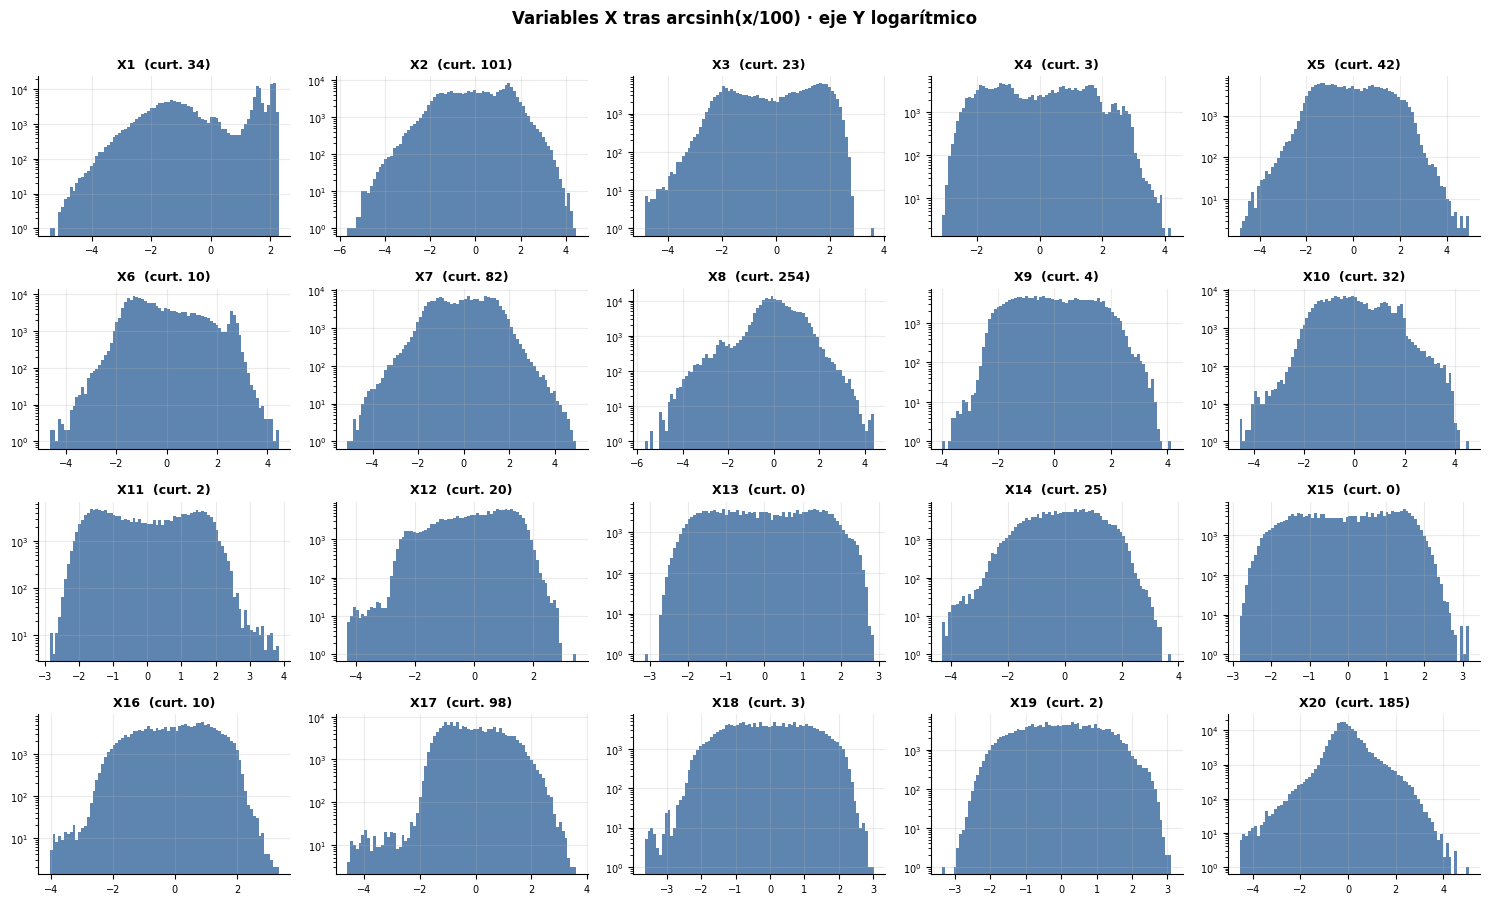

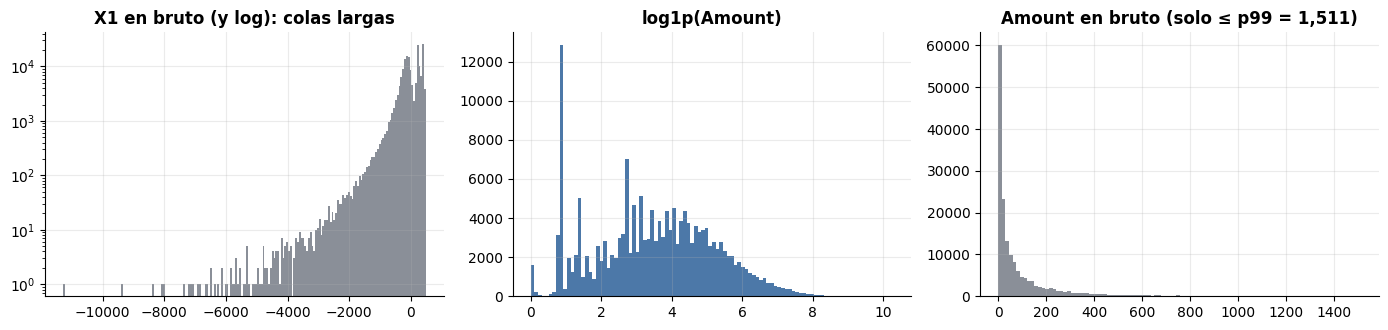

Amount percentiles: {0.5: 33.0, 0.9: 303.3, 0.99: 1510.6, 0.999: 4436.3, 1.0: 29484.8}


In [8]:
fig, ax = plt.subplots(4, 5, figsize=(15, 9))
for a, c in zip(ax.ravel(), XS):
    a.hist(asinh(tr[c]), bins=80, color=AZUL, alpha=.9)
    a.set_title(f"{c}  (curt. {tr[c].kurt():.0f})", fontsize=9); a.set_yscale("log"); a.tick_params(labelsize=7)
plt.suptitle("Variables X tras arcsinh(x/100) · eje Y logarítmico", y=1.0, fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(tr["X1"], bins=200, color=GRIS); ax[0].set_yscale("log"); ax[0].set_title("X1 en bruto (y log): colas largas")
ax[1].hist(np.log1p(tr[IMP]), bins=100, color=AZUL); ax[1].set_title("log1p(Amount)")
p99 = tr[IMP].quantile(.99)
ax[2].hist(tr.loc[tr[IMP] <= p99, IMP], bins=100, color=GRIS); ax[2].set_title(f"Amount en bruto (solo ≤ p99 = {p99:,.0f})")
plt.tight_layout(); plt.show()
print("Amount percentiles:", tr[IMP].quantile([.5, .9, .99, .999, 1]).round(1).to_dict())

In [9]:
# Meseta superior de X1: ¿hay un techo?
meseta = tr["X1"] >= 400
print(f"X1 ≥ 400 (máximo {tr['X1'].max():.0f}, con {int((tr['X1'] == tr['X1'].max()).sum())} filas en el máximo exacto): {meseta.mean():.1%} de las filas · {meseta[y == 1].mean():.1%} de los fraudes")
print("Filas en el máximo exacto por variable (mín–máx):", int(min((tr[c] == tr[c].max()).sum() for c in XS)), "–", int(max((tr[c] == tr[c].max()).sum() for c in XS)), "→ no hay recorte duro (clipping) en ninguna variable")

X1 ≥ 400 (máximo 490, con 2 filas en el máximo exacto): 11.3% de las filas · 0.0% de los fraudes
Filas en el máximo exacto por variable (mín–máx): 1 – 2 → no hay recorte duro (clipping) en ninguna variable


**Lectura.**
- Las `X` están **centradas en ~0** pero con **colas muy pesadas** (curtosis mediana ≫ 0; valores extremos de decenas de desviaciones típicas). Las desviaciones típicas **decrecen de ~390 a ~150**, como si fueran componentes ordenados por varianza.
- **Forma del cuerpo (ver la figura):** tras `arcsinh`, muchas variables **no son campanas**: son **planas / multimodales con bordes abruptos** (casi uniformes en `X13`, `X15`, `X11`, `X18`; con un pico pegado al borde superior en `X1`). Es decir, una cola larga en bruto pero un cuerpo "acotado". Ningún modelo gaussiano de pocas componentes las describe bien, lo que anticipa el techo de los modelos de densidad.
- `X1` tiene una **meseta pegada a su máximo** (~11 % de las filas por encima de 400, con un tope de 490) **donde no hay ningún fraude**; no es un recorte duro (los máximos no se repiten), sino una acumulación natural cerca del límite superior.
- `Amount` es **muy asimétrico**: mediana 33, p99 ≈ 1 500, máximo ≈ 29 000, y su histograma en log muestra **picos en valores concretos** (importes recurrentes; ver sección 5).
- Implicaciones: (i) modelos **sensibles a la escala y a los valores extremos** (distancias, una sola gaussiana, regresión) sufren; (ii) los **árboles** no, porque solo usan el orden de los valores; (iii) por eso se usa `arcsinh(x/100)`/`log1p` (constantes fijas, sin estadísticos aprendidos → sin fuga). **Matiz medido (sección 7):** la transformación es decisiva para un score de distancia de una sola gaussiana (Mahalanobis: AUPR 0,26 en bruto → 0,69 transformado), pero **no mejora** al GMM(3) ni a los árboles en la validación del proyecto. Como el ensemble final son árboles, aquí es higiene y no una palanca de rendimiento.

## 5. Relación de cada variable con el fraude

**Pregunta central del EDA.** ¿Se distingue el fraude de lo normal con estas variables? ¿Es el fraude "un punto raro" (problema de anomalías) o tiene un patrón aprendible (problema supervisado)? La respuesta decide el **tipo de modelo**.

Se mide, para cada variable y sin ajustar ningún modelo: el **AUC univariante** (Mann-Whitney; 0,5 = no separa; el sentido del AUC indica si el fraude tiene valores mayores o menores), la **diferencia de medias tipificada**, el **KS** entre clases y el **AUPR univariante** (usando la variable sola como score, con el signo que mejor funciona).

,AUC,AUC (mejor sentido),IC95 % inf.,IC95 % sup.,dif. medias / desv,KS,AUPR univariante,fraude tiene
variable,,,,,,,,
X14,0.0461,0.9539,0.9372,0.9706,-7.5139,0.8522,0.6336,menor valor
X4,0.9348,0.9348,0.9153,0.9544,3.1873,0.7609,0.2051,mayor valor
X12,0.0663,0.9337,0.9140,0.9534,-6.3257,0.7830,0.5969,menor valor
X11,0.9155,0.9155,0.8935,0.9374,3.8515,0.7629,0.5219,mayor valor
X10,0.0876,0.9124,0.8901,0.9347,-5.3076,0.8125,0.5815,menor valor
X3,0.0942,0.9058,0.8828,0.9288,-4.7344,0.6795,0.2538,menor valor
X7,0.1435,0.8565,0.8293,0.8837,-4.8087,0.6906,0.2055,menor valor
X16,0.1443,0.8557,0.8285,0.8830,-4.8856,0.7230,0.4844,menor valor
X2,0.8552,0.8552,0.8279,0.8824,2.2580,0.6260,0.1386,mayor valor


Variables con AUC ≥ 0,80: 12 de 21 → X14, X4, X12, X11, X10, X3, X7, X16, X2, X9, X17, X1
Con el límite inferior del IC95 % también ≥ 0,80: 10 variables (anchura media del IC: 0.056)
Variables casi sin información (AUC en 0,45–0,55): X13, X15
Mejor AUPR univariante: 0.637 (X17) · prevalencia 0.0017


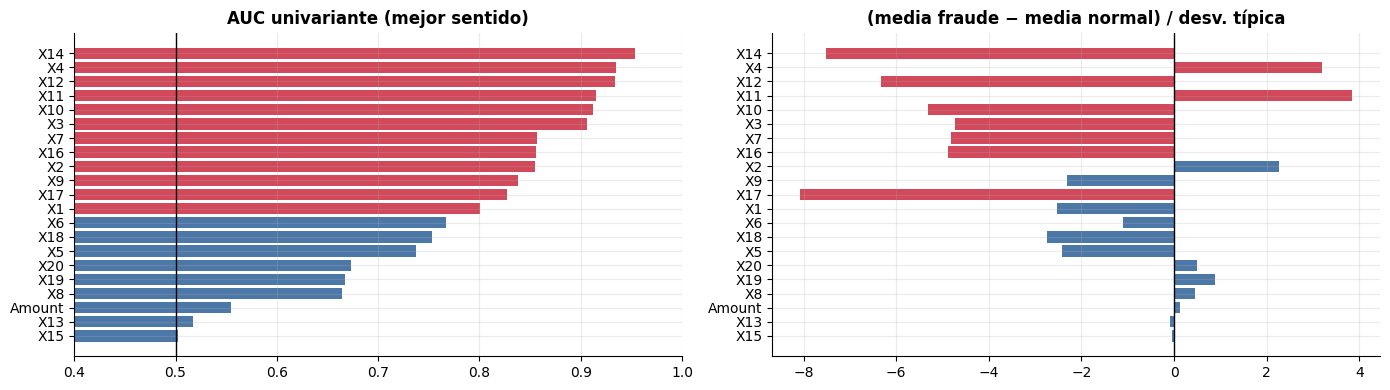

In [10]:
filas = []
for c in XS + [IMP]:
    a, b = F[c].to_numpy(), N[c].to_numpy()
    auc = stats.mannwhitneyu(a, b).statistic / (len(a) * len(b))
    signo = 1 if auc >= .5 else -1
    am = max(auc, 1 - auc)
    q1, q2, n1, n2 = am / (2 - am), 2 * am * am / (1 + am), len(a), len(b)
    se = np.sqrt((am * (1 - am) + (n1 - 1) * (q1 - am * am) + (n2 - 1) * (q2 - am * am)) / (n1 * n2))  # Hanley-McNeil
    filas.append({"variable": c, "AUC": auc, "AUC (mejor sentido)": am, "IC95 % inf.": am - 1.96 * se, "IC95 % sup.": am + 1.96 * se,
                  "dif. medias / desv": (a.mean() - b.mean()) / tr[c].std(),
                  "KS": stats.ks_2samp(a, b).statistic,
                  "AUPR univariante": average_precision_score(y, signo * tr[c]),
                  "fraude tiene": "mayor valor" if auc >= .5 else "menor valor"})
sep = pd.DataFrame(filas).set_index("variable").sort_values("AUC (mejor sentido)", ascending=False)
display(sep)
fuertes = sep[sep["AUC (mejor sentido)"] >= .8]
print(f"Variables con AUC ≥ 0,80: {len(fuertes)} de {len(sep)} → {', '.join(fuertes.index)}")
print(f"Con el límite inferior del IC95 % también ≥ 0,80: {int((sep['IC95 % inf.'] >= .8).sum())} variables (anchura media del IC: {(sep['IC95 % sup.'] - sep['IC95 % inf.']).mean():.3f})")
print(f"Variables casi sin información (AUC en 0,45–0,55): {', '.join(sep[(sep['AUC'] > .45) & (sep['AUC'] < .55)].index)}")
print(f"Mejor AUPR univariante: {sep['AUPR univariante'].max():.3f} ({sep['AUPR univariante'].idxmax()}) · prevalencia {y.mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
o = sep.sort_values("AUC (mejor sentido)")
ax[0].barh(o.index, o["AUC (mejor sentido)"], color=[ROJO if v >= .8 else AZUL for v in o["AUC (mejor sentido)"]])
ax[0].axvline(.5, color="k", lw=1); ax[0].set_title("AUC univariante (mejor sentido)"); ax[0].set_xlim(.4, 1)
ax[1].barh(o.index, o["dif. medias / desv"], color=[ROJO if abs(v) >= 3 else AZUL for v in o["dif. medias / desv"]])
ax[1].axvline(0, color="k", lw=1); ax[1].set_title("(media fraude − media normal) / desv. típica")
plt.tight_layout(); plt.show()

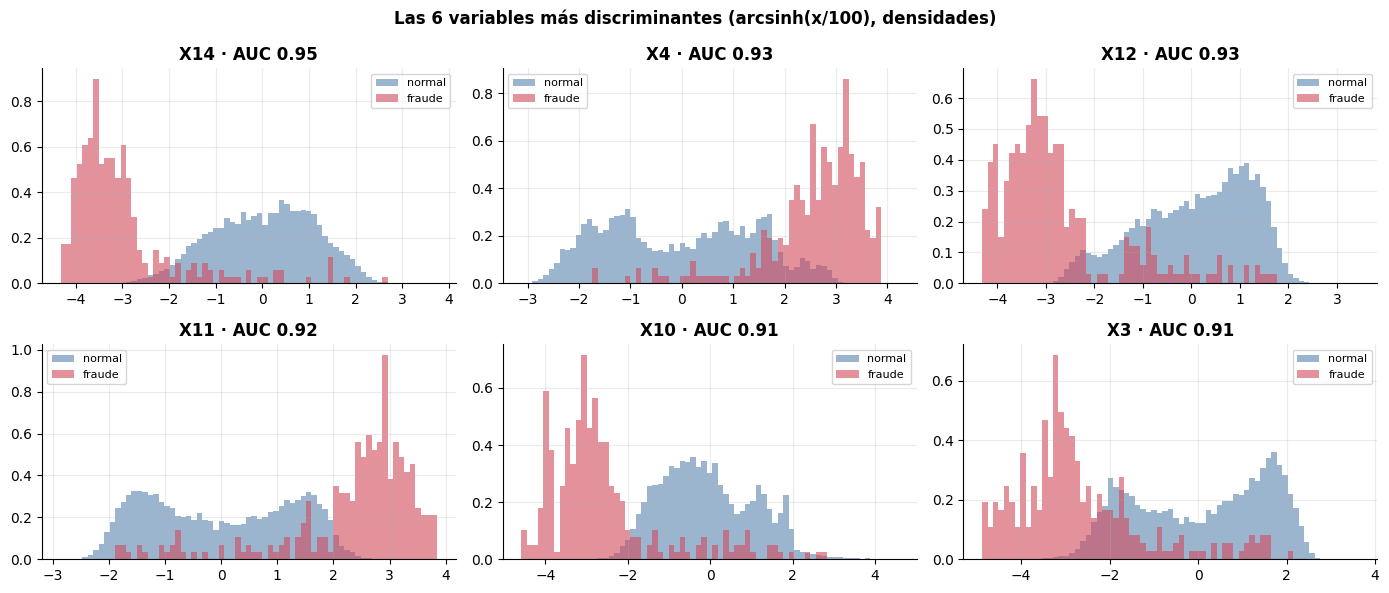

In [11]:
top = sep.index[:6]
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, c in zip(ax.ravel(), top):
    lo, hi = np.percentile(asinh(tr[c]), [0.0, 100.0])
    bins = np.linspace(lo, hi, 70)
    a.hist(asinh(N[c]), bins=bins, density=True, alpha=.55, color=AZUL, label="normal")
    a.hist(asinh(F[c]), bins=bins, density=True, alpha=.6, color=ROJO, label="fraude")
    a.set_title(f"{c} · AUC {sep.loc[c, 'AUC (mejor sentido)']:.2f}"); a.legend(fontsize=8)
plt.suptitle("Las 6 variables más discriminantes (arcsinh(x/100), densidades)", fontweight="bold"); plt.tight_layout(); plt.show()

### Firma de cola del fraude

,cola dominante,% fraudes en esa cola,"× lo esperado (0,2 %)","normal < p0,2","normal > p99,8"
X17,inferior,73.6842,368.4211,0.0739,0.1929
X14,inferior,68.0702,340.3509,0.0841,0.1971
X12,inferior,65.2632,326.3158,0.0877,0.1995
X10,inferior,64.2105,321.0526,0.0907,0.2001
X11,superior,59.6491,298.2456,0.2007,0.0979
X16,inferior,49.4737,247.3684,0.1148,0.1983
X4,superior,38.5965,192.9825,0.2007,0.1340
X9,inferior,36.8421,184.2105,0.1352,0.2007
X18,inferior,35.4386,177.1930,0.1358,0.1935
X3,inferior,30.5263,152.6316,0.1484,0.1977


Variables con ≥ 30 % de los fraudes en una cola extrema: 10 · máximo: 74 % (X17) = 368× lo esperado
Cola inferior: X1, X3, X5, X7, X9, X10, X12, X14, X16, X17, X18
Cola superior: X2, X4, X8, X11


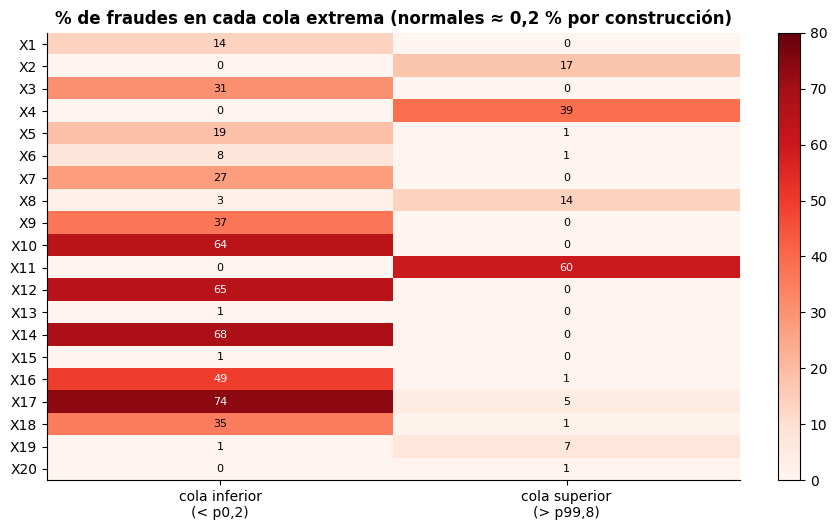

Nº de colas dominantes tocadas por fila (15 variables): mediana fraude 6 · normal 0 · fraudes con ≥ 3 colas: 71% · normales con ≥ 3 colas: 0.15%
AUPR usando solo ese recuento como score: 0.563


In [12]:
# Firma de cola: % de fraudes (y de normales) más allá de los percentiles 0,2 y 99,8 de TODOS los datos.
lo, hi = dd[XS].quantile(.002), dd[XS].quantile(.998)
Fd2, Nd2 = dd[dd[OBJ] == 1], dd[dd[OBJ] == 0]
firma = pd.DataFrame({
    "fraude < p0,2": [(Fd2[c] < lo[c]).mean() * 100 for c in XS], "fraude > p99,8": [(Fd2[c] > hi[c]).mean() * 100 for c in XS],
    "normal < p0,2": [(Nd2[c] < lo[c]).mean() * 100 for c in XS], "normal > p99,8": [(Nd2[c] > hi[c]).mean() * 100 for c in XS]}, index=XS)
firma["cola dominante"] = np.where(firma["fraude < p0,2"] >= firma["fraude > p99,8"], "inferior", "superior")
firma["% fraudes en esa cola"] = firma[["fraude < p0,2", "fraude > p99,8"]].max(axis=1)
firma["× lo esperado (0,2 %)"] = firma["% fraudes en esa cola"] / 0.2
display(firma[["cola dominante", "% fraudes en esa cola", "× lo esperado (0,2 %)", "normal < p0,2", "normal > p99,8"]]
        .sort_values("% fraudes en esa cola", ascending=False))
n_cola = int((firma["% fraudes en esa cola"] >= 30).sum())
print(f"Variables con ≥ 30 % de los fraudes en una cola extrema: {n_cola} · máximo: {firma['% fraudes en esa cola'].max():.0f} % "
      f"({firma['% fraudes en esa cola'].idxmax()}) = {firma['× lo esperado (0,2 %)'].max():.0f}× lo esperado")
print("Cola inferior:", ", ".join(firma.index[(firma['cola dominante'] == 'inferior') & (firma['% fraudes en esa cola'] >= 10)]))
print("Cola superior:", ", ".join(firma.index[(firma['cola dominante'] == 'superior') & (firma['% fraudes en esa cola'] >= 10)]))

fig, ax = plt.subplots(figsize=(8.5, 5.4))
M = firma[["fraude < p0,2", "fraude > p99,8"]].to_numpy()
im = ax.imshow(M, cmap="Reds", vmin=0, vmax=80, aspect="auto"); ax.grid(False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["cola inferior\n(< p0,2)", "cola superior\n(> p99,8)"]); ax.set_yticks(range(20)); ax.set_yticklabels(XS)
for i in range(20):
    for j in range(2):
        ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", color="white" if M[i, j] > 45 else "black", fontsize=8)
ax.set_title("% de fraudes en cada cola extrema (normales ≈ 0,2 % por construcción)"); plt.colorbar(im, fraction=.04)
plt.tight_layout(); plt.show()

# ¿Cuántas de "sus" colas toca cada fila? (solo variables con cola dominante clara)
dom = firma.index[firma["% fraudes en esa cola"] >= 10]
toca = sum(((dd[c] < lo[c]) if firma.loc[c, "cola dominante"] == "inferior" else (dd[c] > hi[c])).astype(int) for c in dom)
print(f"Nº de colas dominantes tocadas por fila ({len(dom)} variables): mediana fraude {toca[dd[OBJ] == 1].median():.0f} · normal {toca[dd[OBJ] == 0].median():.0f}"
      f" · fraudes con ≥ 3 colas: {(toca[dd[OBJ] == 1] >= 3).mean():.0%} · normales con ≥ 3 colas: {(toca[dd[OBJ] == 0] >= 3).mean():.2%}")
print(f"AUPR usando solo ese recuento como score: {average_precision_score(dd[OBJ], toca):.3f}")

**Lectura (el hallazgo central del EDA).**
- **El fraude tiene una *firma de cola*:** es extremo **en el mismo sentido y en muchas variables a la vez**. Cola inferior en `X1, X3, X5, X7, X9, X10, X12, X14, X16, X17, X18` y superior en `X2, X4, X8, X11` (variables con ≥ 10 % de los fraudes en su cola; las demás tienen una firma débil).
- **Una decena de variables** tiene ≥ 30 % de sus fraudes más allá del percentil 0,2 o 99,8 de todos los datos, frente a ~0,2 % de las filas normales: hasta **~370 veces lo esperado** (`X17`).
- **Corrección respecto a la v1:** los histogramas de la v1 se recortaban en los percentiles 0,2 y 99,8, de modo que el "amontonamiento en el borde" que se veía era masa **que seguía más allá del recorte**. Ahora se muestra el rango completo y la tabla cuantifica la cola con rigor.
- **Por qué importa para el modelo:** cada variable es casi una *regla de umbral en la cola*; combinar muchas de ellas (lo que hacen los árboles) es muy potente. Una puntuación **trivial** que solo cuenta cuántas colas toca una fila alcanza un AUPR de ≈ 0,56 (ver cifra impresa). **Cautela:** esa cifra es *optimista y en muestra*, porque elegimos las variables y el sentido de cada cola mirando las etiquetas de los mismos datos; no es un resultado de validación. Sirve para ver que la señal es simple y fuerte, no como rendimiento esperable.
- **→ Refuerza** el uso de árboles y plantea la hipótesis H5 (una variable derivada que cuente colas tocadas).

### Importe: por tramos de valor y por valores exactos

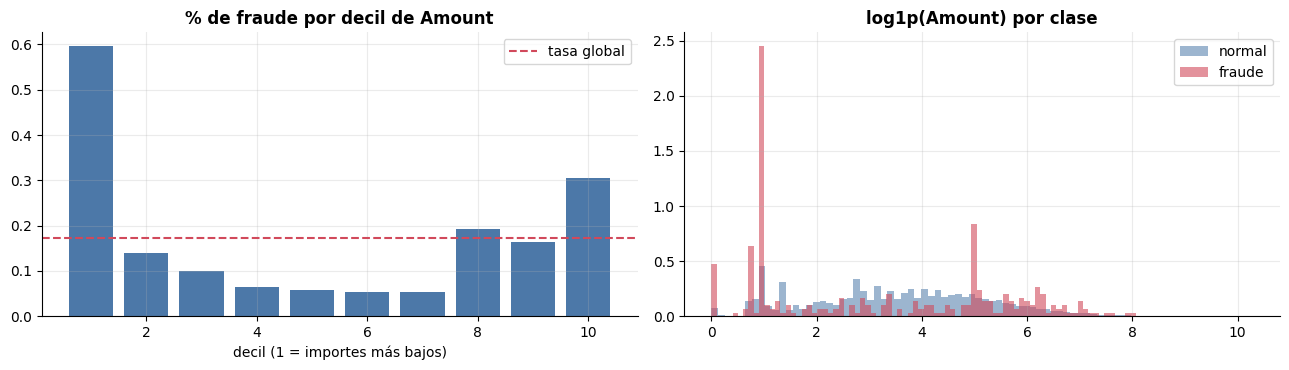

Amount,0,1,2,3,4,5,6,7,8,9
min,0.0000,1.5000,5.3700,13.3800,19.6800,33.0000,55.5000,89.3200,150.0000,303.2600
max,1.5000,5.3700,13.3800,19.6800,33.0000,55.5000,89.3000,150.0000,303.2300,"29,484.8000"
% fraude,0.5970,0.1400,0.0990,0.0640,0.0590,0.0530,0.0530,0.1930,0.1640,0.3040


In [13]:
dec = pd.qcut(tr[IMP].rank(method="first"), 10, labels=False)
tasa_dec = tr.groupby(dec)[OBJ].mean() * 100
lim = tr.groupby(dec)[IMP].agg(["min", "max"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(tasa_dec.index + 1, tasa_dec.values, color=AZUL); ax[0].axhline(y.mean() * 100, color=ROJO, ls="--", label="tasa global")
ax[0].set_title("% de fraude por decil de Amount"); ax[0].set_xlabel("decil (1 = importes más bajos)"); ax[0].legend()
ax[1].hist(np.log1p(N[IMP]), bins=80, density=True, alpha=.55, color=AZUL, label="normal")
ax[1].hist(np.log1p(F[IMP]), bins=80, density=True, alpha=.6, color=ROJO, label="fraude")
ax[1].set_title("log1p(Amount) por clase"); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.concat([lim.round(2), tasa_dec.rename("% fraude").round(3)], axis=1).T)

**Lectura (hallazgo clave).**
- **El fraude NO es solo "un punto raro": tiene un patrón fuerte y aprendible.** Más de la mitad de las variables (ver el recuento impreso arriba) separa las clases por sí sola con AUC ≥ 0,8 (hasta ~0,95), con diferencias de medias de **hasta ~8 desviaciones típicas**, en ambos sentidos (unas variables suben y otras bajan en fraude).
- Hay variables **sin información** individual (`X13` y `X15`, con AUC ≈ 0,5): conviene que el modelo las ignore, no que las trate como señal.
- `Amount` por sí solo apenas discrimina (AUC ≈ 0,45), pero su relación con el fraude **no es monótona**: la tasa es mayor en los importes más bajos (incluidos los de 0) y en los más altos. Un modelo lineal en el importe lo perdería; un árbol no.
- **Forma de la señal:** los histogramas (ahora sobre todo el rango, sin recortar) muestran que el fraude ocupa **una cola** de cada variable, con un sentido distinto por variable. La tabla de la sección siguiente lo cuantifica (*firma de cola*).
- **→ Decisión: enfoque supervisado.** Hay etiquetas y una señal multivariante nítida; un detector de anomalías puro tira esa información. La sección 7 cuantifica cuánto se pierde.

In [14]:
# ¿Se concentra el fraude en importes exactos? (sobre datos deduplicados)
Fd = dd[dd[OBJ] == 1]
vc = Fd[IMP].value_counts().head(8)
tabla_imp = pd.DataFrame({"fraudes con ese importe": vc,
                          "filas totales con ese importe": [int((dd[IMP] == v).sum()) for v in vc.index]})
tabla_imp["tasa de fraude"] = tabla_imp["fraudes con ese importe"] / tabla_imp["filas totales con ese importe"]
tabla_imp["× tasa global"] = tabla_imp["tasa de fraude"] / dd[OBJ].mean()
tabla_imp["% de todos los fraudes"] = 100 * tabla_imp["fraudes con ese importe"] / len(Fd)
tabla_imp.index.name = "importe"
display(tabla_imp)
top3 = tabla_imp["% de todos los fraudes"].head(3).sum()
print(f"Los 3 importes más frecuentes en fraude ({', '.join(f'{v:g}' for v in vc.index[:3])}) reúnen el {top3:.0f} % de los fraudes.")
print(f"Importes distintos entre los {len(Fd)} fraudes: {Fd[IMP].nunique()} · entre {int((dd[OBJ] == 0).sum()):,} normales: {dd.loc[dd[OBJ] == 0, IMP].nunique():,}")

,fraudes con ese importe,filas totales con ese importe,tasa de fraude,× tasa global,% de todos los fraudes
importe,,,,,
1.5000,66,7484,0.0088,5.1588,23.1579
149.9800,18,187,0.0963,56.3075,6.3158
1.1400,12,1627,0.0074,4.3145,4.2105
0.0000,11,1059,0.0104,6.0762,3.8596
1.1600,6,806,0.0074,4.3546,2.1053
18.4600,3,426,0.0070,4.1195,1.0526
1.7700,3,204,0.0147,8.6025,1.0526
3.4200,2,272,0.0074,4.3013,0.7018


Los 3 importes más frecuentes en fraude (1.5, 149.98, 1.14) reúnen el 34 % de los fraudes.
Importes distintos entre los 285 fraudes: 164 · entre 166,432 normales: 25,319


**Lectura (hallazgo no previsto).**
- **Para el fraude, el importe no es una magnitud continua sino un conjunto de valores concretos.** Un importe único (p. ej. 1,50) reúne ~23 % de todos los fraudes y otro (149,98) multiplica por decenas la tasa base de fraude. Los datos están anonimizados, así que **no podemos afirmar a qué corresponden** esos importes (¿pruebas de tarjeta?, ¿precios de catálogo?); solo que son valores recurrentes.
- Cuidado con la interpretación: `1,50` es también el importe normal más repetido (miles de filas), por lo que su tasa de fraude es solo unas pocas veces la global; en cambio `149,98` tiene una tasa de fraude altísima. **La señal está en el valor exacto**, no en su magnitud.
- Esto explica por qué `Amount` tiene AUC ≈ 0,45–0,55 y aun así importa: la información es **discreta y no monótona**.
- **→ Implicación para la Fase 6:** comprobar si un modelo que ve el valor exacto mejora y si los árboles actuales ya lo capturan. *Resultado de la Fase 6:* un indicador explícito de los importes clave **no mejoró** el modelo (los árboles ya los capturan); la *frecuencia* del importe sí dio una mejora pequeña y consistente, aún por debajo del criterio de confirmación (`docs/04_VALIDACION_FASE6.md`).

**¿Y la frecuencia del importe?** Una variante más "limpia" que el valor exacto es la *frecuencia* con la que aparece cada importe (se calcula sin etiquetas). La tabla siguiente mide si la tasa de fraude depende de ella.

In [15]:
cnt = dd[IMP].map(dd[IMP].value_counts())
tramo = pd.cut(cnt, [0, 1, 3, 10, 100, 1000, 1e6], labels=["1 vez", "2–3", "4–10", "11–100", "101–1 000", "> 1 000"])
frec = dd.groupby(tramo, observed=True)[OBJ].agg(filas="count", fraudes="sum", tasa="mean")
frec["× tasa global"] = frec["tasa"] / dd[OBJ].mean()
frec.index.name = "veces que aparece el importe"
display(frec)
print(f"Rango de la tasa de fraude entre tramos: {frec['× tasa global'].min():.1f}× – {frec['× tasa global'].max():.1f}× la global")

,filas,fraudes,tasa,× tasa global
veces que aparece el importe,,,,
1 vez,13256,45,0.0034,1.9858
2–3,13960,24,0.0017,1.0057
4–10,23943,23,0.0010,0.5619
11–100,46088,50,0.0011,0.6346
101–1 000,40924,53,0.0013,0.7576
> 1 000,28546,90,0.0032,1.8443


Rango de la tasa de fraude entre tramos: 0.6× – 2.0× la global


**Lectura.**
- La relación entre la **frecuencia del importe** y el fraude es una **"U" suave** (importes muy raros y muy comunes tienen algo más de fraude), con razones de tasa de ~0,6× a ~2×. Es una señal **modesta** comparada con la del valor exacto (149,98 → ~56×) o la de las colas de las X (hasta ~370×).
- **→ Para la Fase 6:** la frecuencia por sí sola difícilmente mejorará el modelo; si algo aporta es el **valor exacto de unos pocos importes**. No se descarta, pero queda como hipótesis de baja prioridad (H4).

## 6. Correlaciones y estructura de varianza

**Pregunta.** ¿Hay colinealidad entre variables? ¿Aportan información redundante? Afecta a la elección del modelo (regresión/Gaussianas vs. árboles) y a la selección de variables.

Máxima |correlación| entre dos X: 0.034 · media: 0.004
Correlación de Amount con las X (mayores): {'X2': 0.532, 'X20': 0.372, 'X7': 0.366, 'X5': 0.362}


,|r| medio,|r| máximo
Pearson (lineal),0.0035,0.0340
Spearman (rangos),0.0809,0.4431
Pearson entre |X| (magnitudes),0.1905,0.7315


Pares con mayor |Spearman|: {'X6-X8': 0.443, 'X5-X7': 0.43, 'X2-X7': 0.429, 'X1-X3': -0.413, 'X7-X8': -0.389, 'X1-X2': -0.388}


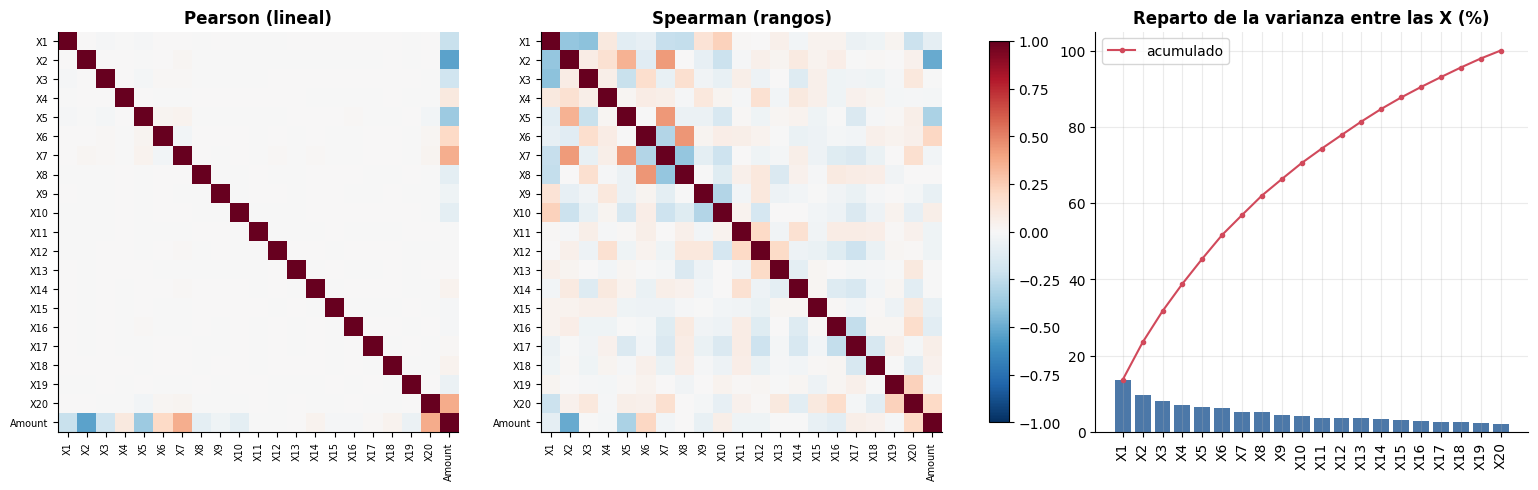

La primera X concentra 13.7% de la varianza; las 10 primeras, 70.5%. Una verdadera PCA concentraría mucho más en las primeras.


In [16]:
cm = tr[XS + [IMP]].corr()
cx = cm.loc[XS, XS].abs().to_numpy().copy(); np.fill_diagonal(cx, 0)
print(f"Máxima |correlación| entre dos X: {cx.max():.3f} · media: {cx[np.triu_indices(20, 1)].mean():.3f}")
ca = cm.loc[XS, IMP].abs().sort_values(ascending=False)
print("Correlación de Amount con las X (mayores):", ca.head(4).round(3).to_dict())
sp = tr[XS + [IMP]].corr(method="spearman")           # dependencia monótona (por rangos)
mag = tr[XS].abs().corr()                              # dependencia entre magnitudes |X|
fuera = lambda m: np.abs(m.to_numpy()).copy() - np.diag(np.abs(np.diag(m.to_numpy())))
comp = pd.DataFrame({
    "|r| medio": [fuera(cm.loc[XS, XS])[np.triu_indices(20, 1)].mean(), fuera(sp.loc[XS, XS])[np.triu_indices(20, 1)].mean(), fuera(mag)[np.triu_indices(20, 1)].mean()],
    "|r| máximo": [fuera(cm.loc[XS, XS]).max(), fuera(sp.loc[XS, XS]).max(), fuera(mag).max()]},
    index=["Pearson (lineal)", "Spearman (rangos)", "Pearson entre |X| (magnitudes)"])
display(comp)
pares = sp.loc[XS, XS].where(np.triu(np.ones((20, 20), bool), 1)).stack().sort_values(key=np.abs, ascending=False).head(6)
print("Pares con mayor |Spearman|:", {f"{a}-{b}": round(v, 3) for (a, b), v in pares.items()})

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for a, m, tit in ((ax[0], cm, "Pearson (lineal)"), (ax[1], sp, "Spearman (rangos)")):
    im = a.imshow(m.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(21)); a.set_xticklabels(m.columns, rotation=90, fontsize=7)
    a.set_yticks(range(21)); a.set_yticklabels(m.columns, fontsize=7); a.grid(False)
    a.set_title(tit)
plt.colorbar(im, ax=ax[:2], fraction=.02)
var = tr[XS].var(); share = var / var.sum()
ax[2].bar(XS, share * 100, color=AZUL); ax[2].plot(XS, share.cumsum() * 100, color=ROJO, marker="o", ms=3, label="acumulado")
ax[2].set_title("Reparto de la varianza entre las X (%)"); ax[2].tick_params(axis="x", rotation=90); ax[2].legend()
plt.show()
print(f"La primera X concentra {share.iloc[0]:.1%} de la varianza; las 10 primeras, {share.iloc[:10].sum():.1%}. Una verdadera PCA concentraría mucho más en las primeras.")

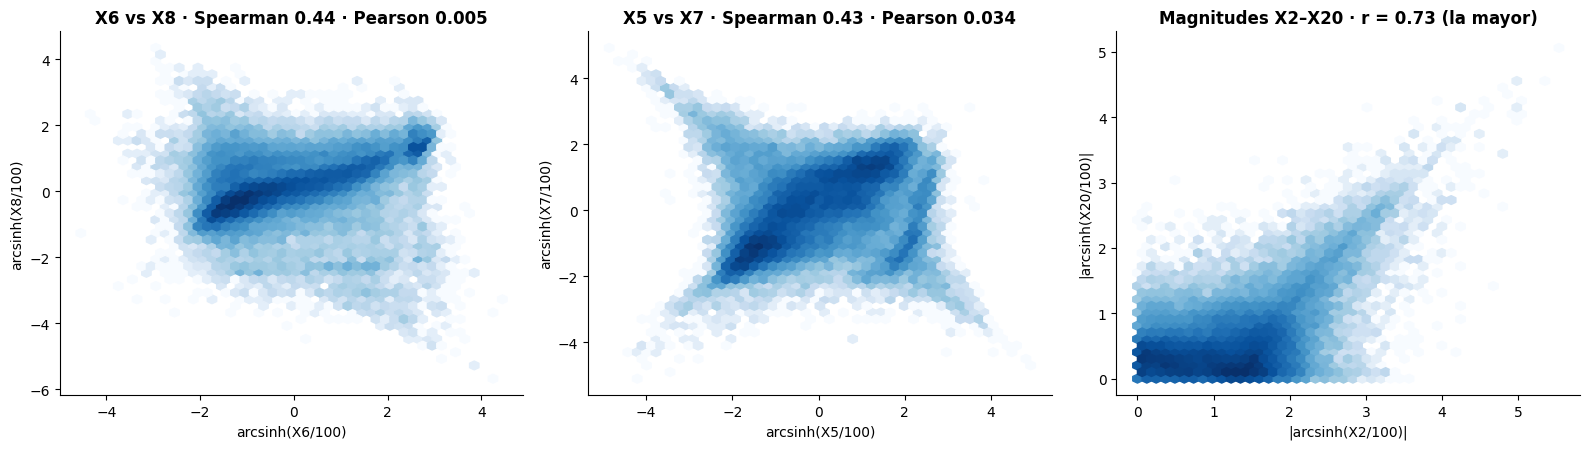

In [17]:
ds = dd.sample(60000, random_state=SEED)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (u, v) in zip(ax[:2], [("X6", "X8"), ("X5", "X7")]):
    hb = a.hexbin(asinh(ds[u]), asinh(ds[v]), gridsize=45, bins="log", cmap="Blues", mincnt=1)
    a.set_xlabel(f"arcsinh({u}/100)"); a.set_ylabel(f"arcsinh({v}/100)"); a.grid(False)
    a.set_title(f"{u} vs {v} · Spearman {sp.loc[u, v]:.2f} · Pearson {cm.loc[u, v]:.3f}")
mm = fuera(mag); iu, ju = np.unravel_index(mm.argmax(), mm.shape); pu, pv = XS[iu], XS[ju]   # par con mayor correlación de magnitudes
ax[2].hexbin(np.abs(asinh(ds[pu])), np.abs(asinh(ds[pv])), gridsize=45, bins="log", cmap="Blues", mincnt=1); ax[2].grid(False)
ax[2].set_xlabel(f"|arcsinh({pu}/100)|"); ax[2].set_ylabel(f"|arcsinh({pv}/100)|"); ax[2].set_title(f"Magnitudes {pu}–{pv} · r = {mag.loc[pu, pv]:.2f} (la mayor)")
plt.tight_layout(); plt.show()

**Lectura.**
- **Linealmente** las 20 `X` están prácticamente incorrelacionadas (|r| medio ≈ 0,004; máx. ≈ 0,03): **no hay colinealidad lineal** que eliminar.
- **Pero no son independientes.** Por rangos (Spearman) hay dependencias de hasta ~0,44 (p. ej. X5–X7, X6–X8) y las **magnitudes** |X| están correlacionadas hasta ~0,73. Es la huella típica de variables de colas pesadas incorrelacionadas pero con dependencia no lineal (cuando una es extrema, otras tienden a serlo). **Una matriz de covarianza lineal no ve esta estructura**; los modelos de árboles pueden explotarla por interacciones.
- Los diagramas de densidad lo muestran: con Pearson ≈ 0 hay **formas claramente estructuradas** (bandas diagonales, "alas" y esquinas con acumulación) y las magnitudes tienden a crecer juntas. Es dependencia no lineal que una covarianza no resume.
- `Amount` se correlaciona de forma moderada con alguna `X` (hasta ~0,5): comparte información, pero no es redundante.
- La varianza decrece suavemente entre `X1` y `X20` (sin "codo"): **no hay un subespacio de baja dimensión** donde "vivan" los datos normales.
- **→ Decisión:** conservar las 21 variables; no aplicar PCA ni selección por redundancia. La conclusión "variables independientes" **sería falsa**: la ausencia de correlación de Pearson no autoriza a asumir independencia (matiz importante para cualquier modelo gaussiano de covarianza completa).

## 7. Colas y valores atípicos: ¿el fraude es un "outlier"?

**Pregunta.** Si el fraude fuese simplemente lo más raro, un detector de anomalías sin etiquetas bastaría. ¿Cuánto del fraude es atípico y cuánto de lo normal también lo es?

,2,3,4,5,6,7,8,9,10
% normal con alguna |z|>k,0.4035,0.1050,0.0328,0.0184,0.0131,0.0092,0.0067,0.0047,0.0037
% fraude con alguna |z|>k,0.9627,0.8983,0.8712,0.8271,0.7424,0.6576,0.5831,0.5085,0.4780
razón,2.3862,8.5552,26.5668,44.8640,56.7132,71.7748,87.4008,108.5609,129.6276


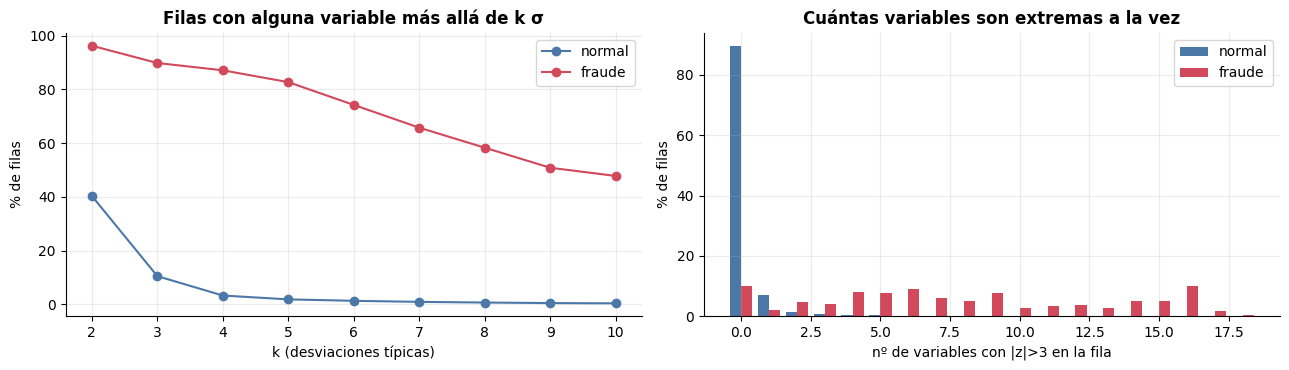

Variables con |z|>3 por fila: mediana 7 en fraude frente a 0 en normales
Filas con ≥ 8 variables extremas: 471 · tasa de fraude entre ellas 29.9% (global 0.17%)
AUPR usando solo ese recuento como score: 0.348


In [18]:
z = (tr[XS] - tr[XS].mean()) / tr[XS].std()
ks = np.arange(2, 11)
curv = pd.DataFrame({
    "normal": [(z[y == 0].abs() > k).any(axis=1).mean() for k in ks],
    "fraude": [(z[y == 1].abs() > k).any(axis=1).mean() for k in ks]}, index=ks)
curv["razón"] = curv["fraude"] / curv["normal"]
display(curv.T.rename(index={"normal": "% normal con alguna |z|>k", "fraude": "% fraude con alguna |z|>k"}))

n_ext = (z.abs() > 3).sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(ks, curv["normal"] * 100, "o-", color=AZUL, label="normal"); ax[0].plot(ks, curv["fraude"] * 100, "o-", color=ROJO, label="fraude")
ax[0].set_xlabel("k (desviaciones típicas)"); ax[0].set_ylabel("% de filas"); ax[0].set_title("Filas con alguna variable más allá de k σ"); ax[0].legend()
mx = int(n_ext.max())
ax[1].bar(np.arange(mx + 1) - .2, np.bincount(n_ext[y == 0], minlength=mx + 1) / (y == 0).sum() * 100, .4, color=AZUL, label="normal")
ax[1].bar(np.arange(mx + 1) + .2, np.bincount(n_ext[y == 1], minlength=mx + 1) / (y == 1).sum() * 100, .4, color=ROJO, label="fraude")
ax[1].set_xlabel("nº de variables con |z|>3 en la fila"); ax[1].set_ylabel("% de filas"); ax[1].set_title("Cuántas variables son extremas a la vez"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Variables con |z|>3 por fila: mediana {n_ext[y == 1].median():.0f} en fraude frente a {n_ext[y == 0].median():.0f} en normales")
print(f"Filas con ≥ 8 variables extremas: {int((n_ext >= 8).sum())} · tasa de fraude entre ellas {y[(n_ext >= 8).to_numpy()].mean():.1%} (global {y.mean():.2%})")
print(f"AUPR usando solo ese recuento como score: {average_precision_score(y, n_ext):.3f}")

In [19]:
# Instrumento de medida (sin etiquetas para ajustar): ¿cuánto separa un score de rareza puro?
Zs = asinh(tr[XS].to_numpy())
mu, S = Zs.mean(0), np.cov(Zs, rowvar=False)
d2 = np.einsum("ij,jk,ik->i", Zs - mu, np.linalg.inv(S), Zs - mu)
d2_cru = np.einsum("ij,jk,ik->i", tr[XS].to_numpy() - tr[XS].mean().to_numpy(),
                   np.linalg.inv(np.cov(tr[XS].to_numpy(), rowvar=False)), tr[XS].to_numpy() - tr[XS].mean().to_numpy())
suma_z = np.abs(z.to_numpy()).sum(1)
ref = pd.DataFrame({
    "AUPR": [average_precision_score(y, d2), average_precision_score(y, d2_cru), average_precision_score(y, suma_z),
             sep["AUPR univariante"].max()],
    "AUC": [stats.mannwhitneyu(d2[y == 1], d2[y == 0]).statistic / ((y == 1).sum() * (y == 0).sum()),
            stats.mannwhitneyu(d2_cru[y == 1], d2_cru[y == 0]).statistic / ((y == 1).sum() * (y == 0).sum()),
            stats.mannwhitneyu(suma_z[y == 1], suma_z[y == 0]).statistic / ((y == 1).sum() * (y == 0).sum()),
            sep["AUC (mejor sentido)"].max()]},
    index=["Mahalanobis (X transformadas)", "Mahalanobis (X crudas)", "Σ|z| (rareza simple)", "mejor variable sola (supervisada)"])
display(ref)
print("Referencia del proyecto (validación cruzada sin fuga): GMM(3) ≈ 0,71 · Isolation Forest ≈ 0,20 · gradient boosting regularizado ≈ 0,83")

,AUPR,AUC
Mahalanobis (X transformadas),0.6892,0.9637
Mahalanobis (X crudas),0.2608,0.9595
Σ|z| (rareza simple),0.3367,0.9598
mejor variable sola (supervisada),0.6374,0.9539


Referencia del proyecto (validación cruzada sin fuga): GMM(3) ≈ 0,71 · Isolation Forest ≈ 0,20 · gradient boosting regularizado ≈ 0,83


**Lectura (matiza la anterior).**
- **El fraude sí es mucho más atípico que lo normal:** ~90 % de los fraudes tiene alguna variable a más de 3σ (frente a ~11 % de las filas normales) y ~83 % a más de 5σ (frente a ~2 %). A la vez **lo extremo no es exclusivo del fraude**: ese ~11 % de normales son unas ~17 000 filas frente a ~260 fraudes, así que un detector de rareza ingenuo tiene muchos falsos positivos (Σ|z|: AUPR ≈ 0,34).
- **Un score de rareza bien construido llega más lejos de lo esperado, sin usar etiquetas:** Mahalanobis sobre las variables transformadas da AUPR ≈ 0,69 (AUC ≈ 0,96), incluso por encima de la mejor variable sola (0,64). **Pero solo si se tratan las colas:** con las X en bruto cae a ≈ 0,26. Esto es evidencia directa de que la transformación `arcsinh` es crítica para modelos de una gaussiana.
- Aun así, el resultado supervisado del proyecto (~0,83) queda **~0,12–0,14 de AUPR por encima** del techo de rareza (GMM(3) ≈ 0,71; Mahalanobis ≈ 0,69) y el Isolation Forest rinde mucho peor (≈ 0,20). Esa diferencia es el valor de usar las etiquetas.
- **→ Decisiones:** (i) tratarlo como problema supervisado; (ii) mantener los detectores no supervisados solo como **candidatos opcionales** (se evaluaron y se excluyeron del ensemble final porque lo empeoran: sus errores no son complementarios a los de los árboles); (iii) conservar `arcsinh/log1p` como protección ante cualquier modelo de distancia o gaussiano.

## 8. Estructura multivariante: ¿se agrupa el fraude?

**Pregunta.** Más allá de variable a variable: ¿ocupa el fraude una región propia del espacio? Se proyecta con PCA (instrumento de visualización, ajustado sin etiquetas).

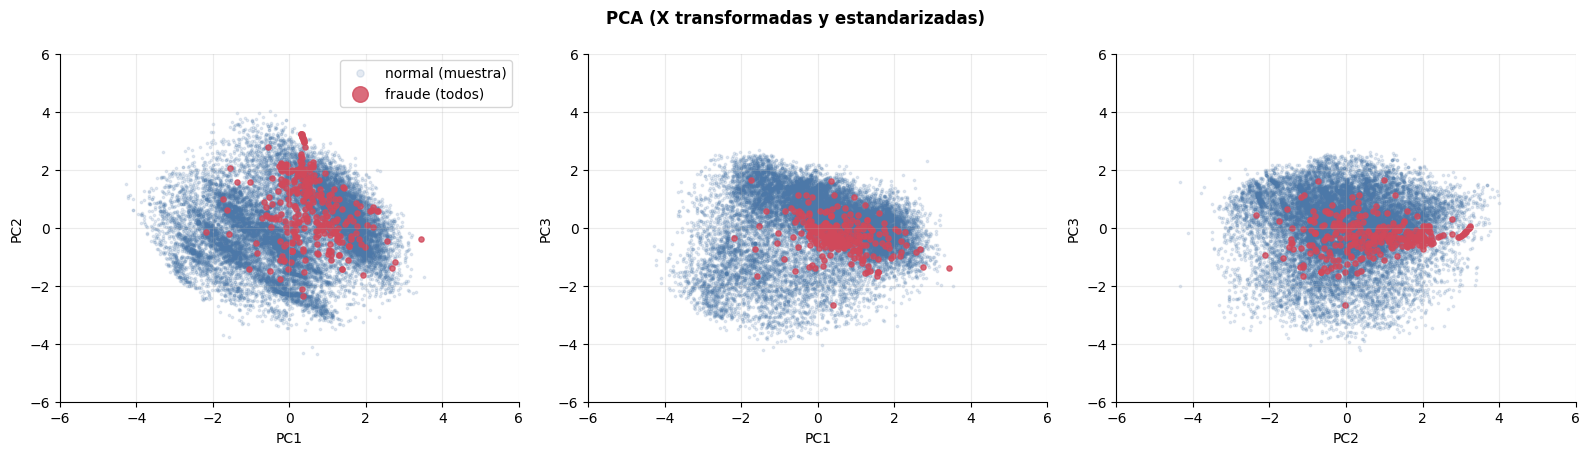

,var. explicada,AUC del componente,AUC (mejor sentido)
PC1,0.1036,0.5991,0.5991
PC2,0.0821,0.6544,0.6544
PC3,0.0699,0.3719,0.6281
PC4,0.0648,0.6722,0.6722
PC5,0.0635,0.5490,0.5490
PC6,0.0596,0.4876,0.5124
PC7,0.0589,0.5858,0.5858
PC8,0.0564,0.3945,0.6055
PC9,0.0538,0.6107,0.6107
PC10,0.0509,0.7385,0.7385


In [20]:
Zs_std = (Zs - Zs.mean(0)) / Zs.std(0)
pca = PCA(n_components=10, random_state=SEED).fit(Zs_std)
P = pca.transform(Zs_std)
rng = np.random.default_rng(SEED)
muestra = np.r_[rng.choice(np.flatnonzero(y == 0), 20000, replace=False), np.flatnonzero(y == 1)]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (i, j) in zip(ax, [(0, 1), (0, 2), (1, 2)]):
    a.scatter(P[muestra][y[muestra] == 0, i], P[muestra][y[muestra] == 0, j], s=3, alpha=.15, color=AZUL, label="normal (muestra)")
    a.scatter(P[y == 1, i], P[y == 1, j], s=14, alpha=.8, color=ROJO, label="fraude (todos)")
    a.set_xlabel(f"PC{i + 1}"); a.set_ylabel(f"PC{j + 1}"); a.set_xlim(-6, 6); a.set_ylim(-6, 6)
ax[0].legend(markerscale=3); plt.suptitle("PCA (X transformadas y estandarizadas)", fontweight="bold"); plt.tight_layout(); plt.show()

auc_pc = [stats.mannwhitneyu(P[y == 1, k], P[y == 0, k]).statistic / ((y == 1).sum() * (y == 0).sum()) for k in range(10)]
tabla_pc = pd.DataFrame({"var. explicada": pca.explained_variance_ratio_, "AUC del componente": auc_pc,
                         "AUC (mejor sentido)": [max(a, 1 - a) for a in auc_pc]}, index=[f"PC{k + 1}" for k in range(10)])
display(tabla_pc)

**Lectura.**
- **Corrección de una expectativa previa:** en las proyecciones principales el fraude **no cae en la periferia** de la nube normal: ocupa su zona **central-derecha (PC1 > 0)**, solapado con muchas filas normales. Ninguno de los 10 primeros componentes lo separa bien (AUC por componente ≤ 0,74).
- Es coherente con la sección 7: el fraude es extremo **variable a variable** (en los bordes de cada rango), pero esos extremos están repartidos en direcciones de baja varianza y **no se alinean con los ejes de máxima varianza**. Un método que parte de la varianza global (PCA, distancia global) lo ve mal.
- La señal está **repartida en muchas dimensiones** a la vez, no en un único eje. Por eso un modelo que combina variables y sus interacciones (**árboles / boosting**) rinde mejor que cualquier score de una sola dimensión.
- **→ Refuerza** la elección de modelos de árboles sobre modelos lineales, PCA o distancias globales.

## 9. ¿Es el fraude un solo patrón o varios?

**Pregunta.** Si hubiese varios tipos de fraude muy distintos, un modelo de densidad sobre lo normal los detectaría peor y habría que vigilar la cobertura de cada subtipo. Se agrupan los 295 fraudes (k-means sobre variables transformadas; solo descriptivo).

In [21]:
Ff = Zs_std[y == 1]
res = []
for k in range(2, 7):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Ff)
    res.append({"k": k, "silueta": silhouette_score(Ff, km.labels_), "tamaños": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
display(pd.DataFrame(res).set_index("k"))

# Distancia media dentro de fraude vs. fraude-normal (muestra) en el espacio estandarizado
from scipy.spatial.distance import cdist
d_ff = cdist(Ff, Ff)[np.triu_indices(len(Ff), 1)].mean()
d_fn = cdist(Ff, Zs_std[rng.choice(np.flatnonzero(y == 0), 2000, replace=False)]).mean()
print(f"Distancia media fraude–fraude: {d_ff:.2f} · fraude–normal: {d_fn:.2f}")
cf = pd.DataFrame(Ff, columns=XS).corr().abs().to_numpy().copy(); np.fill_diagonal(cf, 0)
print(f"Correlación media |r| entre X dentro de los fraudes: {cf[np.triu_indices(20, 1)].mean():.3f} (en el total: {cx[np.triu_indices(20, 1)].mean():.3f})")

,silueta,tamaños
k,,
2,0.4024,"[227, 68]"
3,0.2391,"[143, 88, 64]"
4,0.2478,"[109, 87, 64, 35]"
5,0.2282,"[108, 87, 37, 36, 27]"
6,0.2529,"[93, 84, 57, 36, 13, 12]"


Distancia media fraude–fraude: 8.02 · fraude–normal: 10.23
Correlación media |r| entre X dentro de los fraudes: 0.407 (en el total: 0.004)


Estabilidad (ARI): entre semillas 1.000 · bajo remuestreo bootstrap 0.949  (1 = idéntica)


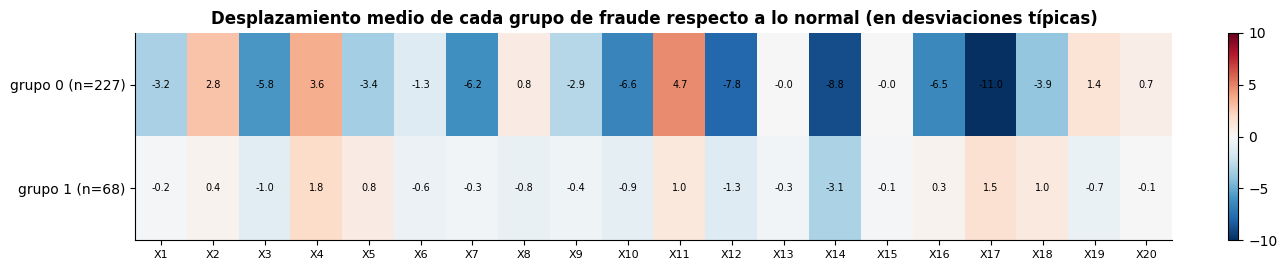

,mediana,"% = 1,50",% = 0,"% = 149,98"
grupo 0 (n=227),27.0000,24.2291,3.5242,7.9295
grupo 1 (n=68),4.1900,25.0000,5.8824,0.0000


Desplazamiento absoluto medio: 4.1σ (grupo 0) frente a 0.8σ (grupo 1)


In [22]:
# ¿Es estable la partición en 2 grupos? (semillas y remuestreo) y ¿qué los distingue?
from sklearn.metrics import adjusted_rand_score
labs = [KMeans(2, n_init=10, random_state=s).fit_predict(Ff) for s in range(10)]
ari_sem = float(np.mean([adjusted_rand_score(labs[0], l) for l in labs[1:]]))
base = KMeans(2, n_init=10, random_state=SEED).fit(Ff)
rng_b = np.random.default_rng(SEED)
ari_boot = float(np.mean([adjusted_rand_score(base.labels_, KMeans(2, n_init=5, random_state=SEED).fit(Ff[rng_b.choice(len(Ff), len(Ff))]).predict(Ff)) for _ in range(30)]))
print(f"Estabilidad (ARI): entre semillas {ari_sem:.3f} · bajo remuestreo bootstrap {ari_boot:.3f}  (1 = idéntica)")

g = base.labels_ if (base.labels_ == 0).sum() >= (base.labels_ == 1).sum() else 1 - base.labels_
Fr = tr[y == 1].reset_index(drop=True)
perfil = (Fr.groupby(g)[XS].mean() - N[XS].mean()) / tr[XS].std()
perfil.index = [f"grupo {i} (n={(g == i).sum()})" for i in (0, 1)]
fig, ax = plt.subplots(figsize=(13, 2.8))
im = ax.imshow(perfil.to_numpy(), cmap="RdBu_r", vmin=-10, vmax=10, aspect="auto"); ax.grid(False)
ax.set_xticks(range(20)); ax.set_xticklabels(XS, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(perfil.index)
for i in range(2):
    for j in range(20):
        ax.text(j, i, f"{perfil.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Desplazamiento medio de cada grupo de fraude respecto a lo normal (en desviaciones típicas)"); plt.colorbar(im, fraction=.02)
plt.tight_layout(); plt.show()

amt = Fr.groupby(g)[IMP].agg(mediana="median", **{"% = 1,50": lambda s: (s == 1.5).mean() * 100, "% = 0": lambda s: (s == 0).mean() * 100,
                                                  "% = 149,98": lambda s: (s == 149.98).mean() * 100})
amt.index = perfil.index
display(amt)
fuerza = perfil.abs().mean(axis=1)
print(f"Desplazamiento absoluto medio: {fuerza.iloc[0]:.1f}σ (grupo 0) frente a {fuerza.iloc[1]:.1f}σ (grupo 1)")

**Lectura.**
- **Hay dos subpoblaciones de fraude, y la partición es estable.** Con k = 2 la silueta es ≈ 0,40 (grupos de ~227 y ~68) y la partición se reproduce prácticamente igual con otras semillas y con remuestreo bootstrap (ARI ≈ 1 entre semillas y > 0,9 bajo remuestreo; ver cifras). Para k ≥ 3 la silueta cae a ≈ 0,23–0,25 sin estructura más fina.
- **El perfil las distingue por *intensidad*, no por dirección:** el **grupo grande ("fraude fuerte")** está desplazado muchas desviaciones típicas en casi todas las variables informativas (hasta ≈ −10σ en `X17`); el **grupo pequeño ("fraude suave")** tiene desplazamientos leves (≈ 1σ en la mayoría; solo `X14` y `X4` destacan). Tienen el mismo sentido en cada variable, pero distinta magnitud.
- **Importes:** `149,98` aparece solo en el grupo fuerte y el grupo suave tiene importes típicamente menores.
- La correlación elevada entre X *dentro* de los fraudes (|r| medio ≈ 0,41 frente a ≈ 0,004 global) es en buena parte el reflejo de **mezclar dos grupos de intensidad distinta**.
- **Cautela:** el grupo suave son ~68 puntos; la partición es estable pero lo que se puede estimar de él es limitado.
- **→ Implicaciones:** (i) el **fraude suave será el más difícil de detectar**: un score que mide intensidad (rareza, número de colas tocadas) lo perderá justo a él; (ii) hipótesis H6: los fraudes peor puntuados por el modelo pertenecen sobre todo a este grupo; (iii) con tan pocos puntos no se justifica un modelo por subtipo: se mantiene un modelo general y regularizado.

## 10. Construcción vs producción

**Pregunta.** ¿Se parece el fichero que se puntúa al que se usa para entrenar? Si no, la validación sobre construcción no representa la producción (*dataset shift*). Además: ¿hay filas de producción que ya están en construcción?

In [23]:
pr_x = pr.drop(columns=OBJ)
filas = []
for c in XS + [IMP]:
    ks_ = stats.ks_2samp(tr[c], pr_x[c])
    filas.append({"variable": c, "dif. medias tipificada": (pr_x[c].mean() - tr[c].mean()) / tr[c].std(),
                  "KS": ks_.statistic, "p-valor KS": ks_.pvalue,
                  "ratio de desv.": pr_x[c].std() / tr[c].std()})
deriva = pd.DataFrame(filas).set_index("variable")
display(deriva.describe().loc[["min", "max"]])
print(f"Máx. |dif. de medias tipificada| = {deriva['dif. medias tipificada'].abs().max():.4f} · máx. KS = {deriva['KS'].max():.4f} "
      f"· variables con p<0,05: {(deriva['p-valor KS'] < .05).sum()} de {len(deriva)} (esperadas por azar: ~{0.05 * len(deriva):.1f})")

# Validación adversaria: ¿puede un modelo distinguir de qué fichero viene una fila?
a = pd.concat([tr.drop(columns=OBJ).drop_duplicates().assign(t=0), pr_x.drop_duplicates().assign(t=1)], ignore_index=True)
t = a.pop("t").to_numpy()
idx = np.random.default_rng(SEED).permutation(len(a)); h = len(a) // 2
adv = HistGradientBoostingClassifier(max_iter=100, random_state=SEED).fit(a.to_numpy()[idx[:h]], t[idx[:h]])
p = adv.predict_proba(a.to_numpy()[idx[h:]])[:, 1]; tv = t[idx[h:]]
auc_adv = stats.mannwhitneyu(p[tv == 1], p[tv == 0]).statistic / ((tv == 1).sum() * (tv == 0).sum())
print(f"AUC de la validación adversaria (0,5 = indistinguibles): {auc_adv:.3f}")

,dif. medias tipificada,KS,p-valor KS,ratio de desv.
min,-0.0047,0.0015,0.0644,0.9957
max,0.0043,0.0050,0.9977,1.0786


Máx. |dif. de medias tipificada| = 0.0047 · máx. KS = 0.0050 · variables con p<0,05: 0 de 21 (esperadas por azar: ~1.1)


AUC de la validación adversaria (0,5 = indistinguibles): 0.500


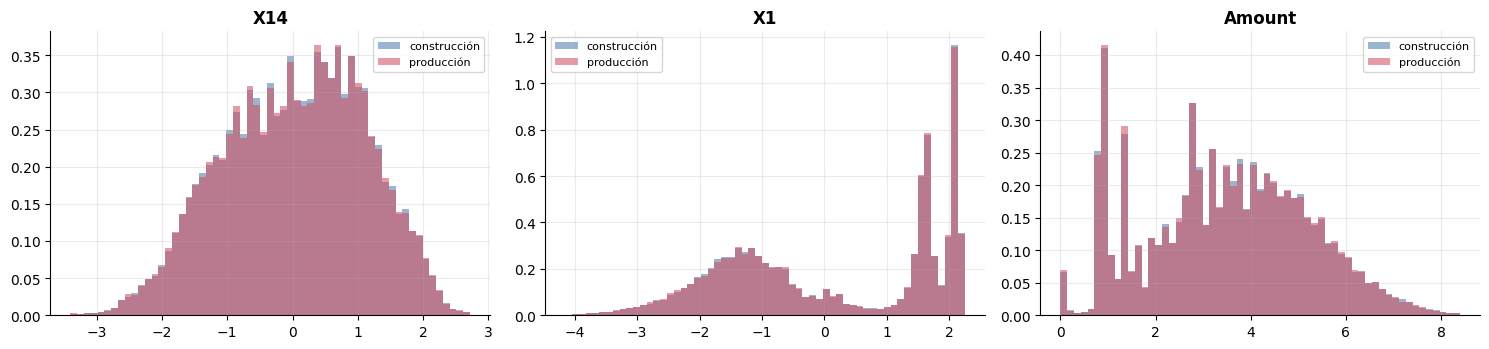

Filas de producción idénticas a una fila de construcción: 4314 de 113923 (3.79%)
  …de ellas, etiquetadas como fraude en construcción: 6


Duplicados dentro de producción: 2109 (1.85%) · en construcción: 2.44%


In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, c in zip(ax, ["X14", "X1", IMP]):
    f = (lambda v: np.log1p(v)) if c == IMP else asinh
    bins = np.linspace(*np.percentile(f(tr[c]), [.1, 99.9]), 60)
    a_.hist(f(tr[c]), bins=bins, density=True, alpha=.55, color=AZUL, label="construcción")
    a_.hist(f(pr_x[c]), bins=bins, density=True, alpha=.55, color=ROJO, label="producción"); a_.set_title(c); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

clave = XS + [IMP]
tr_u = tr.drop_duplicates()
m = pr_x.merge(tr_u, on=clave, how="left", indicator=True)
coinc = m["_merge"] == "both"
print(f"Filas de producción idénticas a una fila de construcción: {coinc.sum()} de {len(pr_x)} ({coinc.mean():.2%})")
print(f"  …de ellas, etiquetadas como fraude en construcción: {int(m.loc[coinc, OBJ].sum())}")
print(f"Duplicados dentro de producción: {pr_x.duplicated().sum()} ({pr_x.duplicated().mean():.2%}) · en construcción: {tr.drop(columns=OBJ).duplicated().mean():.2%}")

**Lectura.**
- **Producción y construcción son estadísticamente indistinguibles**: diferencias de medias tipificadas < 0,005, KS ≤ 0,005, **ninguna de las 21 variables con p<0,05** en el test KS y una **validación adversaria con AUC ≈ 0,50**.
- **→ Decisión:** la validación sobre construcción **es representativa** de producción, y **no hay motivo para ajustar nada con producción** (P-05): ni escaladores, ni modelos, ni umbrales. El proyecto solo la puntúa.
- Existe un pequeño solapamiento de **filas exactamente repetidas** entre ambos ficheros (≈4 %), casi todas normales. Un modelo flexible las reconoce, y está bien que lo haga, pero **no se ha diseñado ninguna regla de búsqueda por coincidencia**: no sería generalizable ni defendible, y aportaría poco (solo un puñado de fraudes etiquetados coinciden).

## 11. Cuánto ruido tiene la métrica

**Pregunta.** Con ~57 fraudes por pliegue, ¿qué parte de las diferencias entre modelos es señal y cuál es azar? Se mide con un score *fijo* (la mejor variable sola, sin entrenar nada): toda la variación entre pliegues es puro muestreo.

Score fijo = X14: AUPR en 300 'pliegues' aleatorios del 20 % → media 0.633, desv. 0.061, rango p5–p95 [0.524, 0.723]


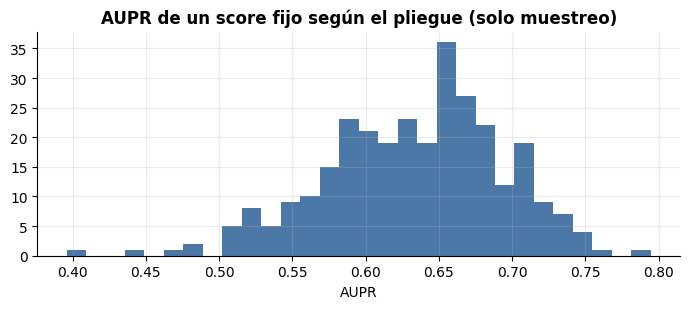

In [25]:
score = (1 if sep.loc[sep.index[0], "AUC"] >= .5 else -1) * dd[sep.index[0]].to_numpy()
yd = dd[OBJ].to_numpy(int)
rng = np.random.default_rng(SEED)
ap = []
for _ in range(300):
    idx0 = rng.permutation(np.flatnonzero(yd == 0))[:int(len(yd) * .2)]
    idx1 = rng.permutation(np.flatnonzero(yd == 1))[:int(yd.sum() * .2)]
    ii = np.r_[idx0, idx1]
    ap.append(average_precision_score(yd[ii], score[ii]))
ap = np.array(ap)
print(f"Score fijo = {sep.index[0]}: AUPR en 300 'pliegues' aleatorios del 20 % → media {ap.mean():.3f}, desv. {ap.std():.3f}, "
      f"rango p5–p95 [{np.percentile(ap, 5):.3f}, {np.percentile(ap, 95):.3f}]")
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.hist(ap, bins=30, color=AZUL); ax.set_title("AUPR de un score fijo según el pliegue (solo muestreo)")
ax.set_xlabel("AUPR"); plt.tight_layout(); plt.show()

**Lectura.**
- Incluso sin entrenar nada, el AUPR **oscila varios centésimos solo por qué fraudes caen en el pliegue**. Los modelos del proyecto muestran una desviación entre pliegues de ≈ 0,05.
- **Por tanto, diferencias de unas milésimas (hgb 0,831 · ensemble 0,834) NO son significativas.** El proyecto lo declara así y justifica el ensemble por robustez, no por mejora demostrada.
- **→ Decisiones:** validación **repetida** (varias particiones), informar siempre media y desviación, y no sobre-interpretar rankings de modelos que quedan dentro del ruido.

In [26]:
# El mapa se construye con cifras calculadas en las celdas anteriores (nada escrito a mano).
k_dup = int(dup_extra.sum()); n_dedup = len(tr) - k_dup
filas = [
    ("Deduplicar antes de particionar", f"{k_dup:,} copias sobrantes ({k_dup / len(tr):.1%}); grupos de hasta {int(multiplicidad.max())} copias; {int(tr.loc[dup_todas, OBJ].sum())} filas de fraude en grupos repetidos", f"{n_dedup:,} filas, {int(tr.loc[~dup_extra, OBJ].sum())} fraudes"),
    ("Métrica AUPR; accuracy descartado", f"prevalencia {prev:.4%} (1 de cada {1 / prev:,.0f}); aleatorio = {prev:.4f}", "Sec. 3"),
    ("Particiones estratificadas", f"~{dd[OBJ].sum() / 5:.0f} fraudes por pliegue (K=5)", "Sec. 3"),
    ("Validación repetida, sin temporal; no sobre-interpretar milésimas", f"sin fechas; desv. del AUPR entre pliegues por puro muestreo = {ap.std():.3f}", "Sec. 11"),
    ("Enfoque supervisado", f"{len(fuertes)} de {len(sep)} variables con AUC ≥ 0,8 (máx. {sep['AUC (mejor sentido)'].max():.2f}); diferencias de hasta {sep['dif. medias / desv'].abs().max():.1f} σ", "Sec. 5"),
    ("Detectores no supervisados solo como candidatos opcionales", f"rareza sola: AUPR máx. {ref['AUPR'].iloc[:3].max():.2f} (Mahalanobis/Σ|z|) frente a ~0,83 supervisado; fraude atípico: {curv.loc[3, 'fraude']:.0%} vs normal {curv.loc[3, 'normal']:.0%} con alguna |z|>3", "Sec. 7"),
    ("Árboles (boosting/bosques) y no modelos lineales", f"señal repartida en muchas dimensiones (sec. 8), no monótona en Amount, y dependencia no lineal entre X: |Pearson| máx. {comp.loc['Pearson (lineal)', '|r| máximo']:.3f} pero |Spearman| máx. {comp.loc['Spearman (rangos)', '|r| máximo']:.2f} y entre magnitudes {comp.loc['Pearson entre |X| (magnitudes)', '|r| máximo']:.2f}", "Sec. 5, 6, 8"),
    ("Regularización fuerte del boosting", f"solo {int(yd.sum())} positivos; curtosis hasta {desc.loc[XS, 'kurt'].max():.0f}", "Sec. 3, 4"),
    ("arcsinh/log1p: crítico para modelos de una gaussiana, irrelevante para árboles", f"curtosis mediana de las X = {desc.loc[XS, 'kurt'].median():.1f}; Mahalanobis AUPR {ref['AUPR'].iloc[1]:.2f} en bruto → {ref['AUPR'].iloc[0]:.2f} transformado", "Sec. 4, 7"),
    ("No tocar Amount = 0 con transformaciones que lo oculten", f"{tasa1 / tasa0:.1f}× más frecuente en fraude (p = {p_cero:.0e})", "Sec. 2"),
    ("Amount: conservar el valor exacto (no solo log)", f"{top3:.0f} % de los fraudes en solo 3 importes exactos; importe {tabla_imp.index[1]:g}: {tabla_imp['× tasa global'].iloc[1]:.0f}× la tasa global", "Sec. 5"),
    ("Conservar las 21 variables; sin PCA ni selección por redundancia", f"sin colinealidad lineal (máx. |r| = {cx.max():.3f}); sin subespacio de baja dimensión (la 1ª X solo explica {share.iloc[0]:.0%} de la varianza)", "Sec. 6"),
    ("No ajustar nada con producción (P-05)", f"AUC adversaria {auc_adv:.3f}; máx. |dif. medias tip.| {deriva['dif. medias tipificada'].abs().max():.3f}", "Sec. 10"),
    ("No explotar coincidencias exactas producción–construcción", f"{coinc.mean():.1%} de filas repetidas, {int(m.loc[coinc, OBJ].sum())} fraudes etiquetados", "Sec. 10"),
    ("Árboles porque cada variable es una regla de umbral en la cola", f"{n_cola} variables con ≥ 30 % de fraudes en una cola extrema (máx. {firma['× lo esperado (0,2 %)'].max():.0f}× lo esperado); contar colas tocadas da AUPR {average_precision_score(dd[OBJ], toca):.2f} con una regla trivial", "Sec. 5"),
    ("Modelo general y regularizado (sin modelos por subtipo)", f"dos grupos de fraude estables (ARI {ari_boot:.2f}): n={int((g == 0).sum())} fuerte y n={int((g == 1).sum())} suave; el suave se desplaza {fuerza.iloc[1]:.1f}σ de media frente a {fuerza.iloc[0]:.1f}σ", "Sec. 9"),
    ("El orden de filas no se usa; el CSV respeta el orden de producción", f"KS de posición de fraudes p = {p_orden:.2f}; autocorrelación ≈ 0", "Sec. 2"),
    ("Ensemble por rangos (escalas heterogéneas)", "probabilidades de árboles y log-verosimilitudes no son comparables directamente", "Sec. 7"),
]
mapa = pd.DataFrame(filas, columns=["Decisión del proyecto", "Hallazgo que la respalda (calculado en este notebook)", "Evidencia"])
display(Markdown("## 12. Mapa hallazgo → decisión"))
lineas = ["| " + " | ".join(mapa.columns) + " |", "|" + "---|" * len(mapa.columns)]
lineas += ["| " + " | ".join(str(v).replace("|", "/") for v in fila) + " |" for fila in mapa.itertuples(index=False)]
display(Markdown(chr(10).join(lineas)))

## 12. Mapa hallazgo → decisión

| Decisión del proyecto | Hallazgo que la respalda (calculado en este notebook) | Evidencia |
|---|---|---|
| Deduplicar antes de particionar | 4,167 copias sobrantes (2.4%); grupos de hasta 49 copias; 16 filas de fraude en grupos repetidos | 166,717 filas, 285 fraudes |
| Métrica AUPR; accuracy descartado | prevalencia 0.1709% (1 de cada 585); aleatorio = 0.0017 | Sec. 3 |
| Particiones estratificadas | ~57 fraudes por pliegue (K=5) | Sec. 3 |
| Validación repetida, sin temporal; no sobre-interpretar milésimas | sin fechas; desv. del AUPR entre pliegues por puro muestreo = 0.061 | Sec. 11 |
| Enfoque supervisado | 12 de 21 variables con AUC ≥ 0,8 (máx. 0.95); diferencias de hasta 8.1 σ | Sec. 5 |
| Detectores no supervisados solo como candidatos opcionales | rareza sola: AUPR máx. 0.69 (Mahalanobis/Σ/z/) frente a ~0,83 supervisado; fraude atípico: 90% vs normal 11% con alguna /z/>3 | Sec. 7 |
| Árboles (boosting/bosques) y no modelos lineales | señal repartida en muchas dimensiones (sec. 8), no monótona en Amount, y dependencia no lineal entre X: /Pearson/ máx. 0.034 pero /Spearman/ máx. 0.44 y entre magnitudes 0.73 | Sec. 5, 6, 8 |
| Regularización fuerte del boosting | solo 285 positivos; curtosis hasta 254 | Sec. 3, 4 |
| arcsinh/log1p: crítico para modelos de una gaussiana, irrelevante para árboles | curtosis mediana de las X = 21.7; Mahalanobis AUPR 0.26 en bruto → 0.69 transformado | Sec. 4, 7 |
| No tocar Amount = 0 con transformaciones que lo oculten | 6.5× más frecuente en fraude (p = 6e-07) | Sec. 2 |
| Amount: conservar el valor exacto (no solo log) | 34 % de los fraudes en solo 3 importes exactos; importe 149.98: 56× la tasa global | Sec. 5 |
| Conservar las 21 variables; sin PCA ni selección por redundancia | sin colinealidad lineal (máx. /r/ = 0.034); sin subespacio de baja dimensión (la 1ª X solo explica 14% de la varianza) | Sec. 6 |
| No ajustar nada con producción (P-05) | AUC adversaria 0.500; máx. /dif. medias tip./ 0.005 | Sec. 10 |
| No explotar coincidencias exactas producción–construcción | 3.8% de filas repetidas, 6 fraudes etiquetados | Sec. 10 |
| Árboles porque cada variable es una regla de umbral en la cola | 10 variables con ≥ 30 % de fraudes en una cola extrema (máx. 368× lo esperado); contar colas tocadas da AUPR 0.56 con una regla trivial | Sec. 5 |
| Modelo general y regularizado (sin modelos por subtipo) | dos grupos de fraude estables (ARI 0.95): n=227 fuerte y n=68 suave; el suave se desplaza 0.8σ de media frente a 4.1σ | Sec. 9 |
| El orden de filas no se usa; el CSV respeta el orden de producción | KS de posición de fraudes p = 0.84; autocorrelación ≈ 0 | Sec. 2 |
| Ensemble por rangos (escalas heterogéneas) | probabilidades de árboles y log-verosimilitudes no son comparables directamente | Sec. 7 |

### 12b. Verificación automática de las afirmaciones del texto

Cada cifra citada en las celdas de *Lectura* se contrasta aquí con los datos de esta ejecución. Si los datos cambiasen y alguna afirmación dejase de cumplirse, **el notebook se detiene** en lugar de dejar un texto desactualizado.

In [27]:
# Verificación automática: cada afirmación numérica del texto se contrasta con los datos. Si alguna falla, el notebook se detiene.
inf_ = set(firma.index[(firma["cola dominante"] == "inferior") & (firma["% fraudes en esa cola"] >= 10)])
sup_ = set(firma.index[(firma["cola dominante"] == "superior") & (firma["% fraudes en esa cola"] >= 10)])
sil2 = float(pd.DataFrame(res).set_index("k").loc[2, "silueta"])
afirmaciones = [
    ("Prevalencia ≈ 0,17 %", f"{prev:.4%}", 0.0015 < prev < 0.0019),
    ("4 167 copias sobrantes; 285 fraudes únicos", f"{k_dup} / {int(dd[OBJ].sum())}", k_dup == 4167 and int(dd[OBJ].sum()) == 285),
    ("El orden de filas no es informativo (KS p > 0,05)", f"p = {p_orden:.2f}", p_orden > 0.05),
    ("Amount = 0 es 6–7 veces más frecuente en fraude", f"{tasa1 / tasa0:.1f}×", 6 <= tasa1 / tasa0 <= 7),
    ("≥ 12 variables con AUC ≥ 0,80; X13 y X15 sin información (AUC < 0,55)", f"{len(fuertes)}", len(fuertes) >= 12 and sep.loc[["X13", "X15"], "AUC (mejor sentido)"].max() < .55),
    ("≥ 10 variables con ≥ 30 % de fraudes en una cola extrema", f"{n_cola}", n_cola >= 10),
    ("Colas dominantes: inferior en 11 variables y superior en X2, X4, X8, X11", f"{sorted(inf_)} / {sorted(sup_)}",
     inf_ == {"X1", "X3", "X5", "X7", "X9", "X10", "X12", "X14", "X16", "X17", "X18"} and sup_ == {"X2", "X4", "X8", "X11"}),
    ("Pearson entre X < 0,05 pero Spearman > 0,4 y magnitudes > 0,7", f"{comp.iloc[0, 1]:.3f} / {comp.iloc[1, 1]:.2f} / {comp.iloc[2, 1]:.2f}", comp.iloc[0, 1] < .05 and comp.iloc[1, 1] > .4 and comp.iloc[2, 1] > .7),
    ("Fraude con alguna |z|>3: ≥ 85 % (normal ≤ 12 %)", f"{curv.loc[3, 'fraude']:.0%} / {curv.loc[3, 'normal']:.0%}", curv.loc[3, "fraude"] >= .85 and curv.loc[3, "normal"] <= .12),
    ("Mahalanobis: AUPR > 0,65 transformado y < 0,30 en bruto", f"{ref['AUPR'].iloc[0]:.2f} / {ref['AUPR'].iloc[1]:.2f}", ref["AUPR"].iloc[0] > .65 and ref["AUPR"].iloc[1] < .30),
    ("Ningún componente principal separa con AUC > 0,80", f"{tabla_pc['AUC (mejor sentido)'].max():.2f}", tabla_pc["AUC (mejor sentido)"].max() < .8),
    ("k = 2: silueta 0,35–0,45 y partición estable (ARI > 0,9)", f"{sil2:.2f} / {ari_sem:.2f} / {ari_boot:.2f}", .35 < sil2 < .45 and ari_sem > .9 and ari_boot > .9),
    ("Grupo suave: desplazamiento medio < 50 % del fuerte", f"{fuerza.iloc[1]:.1f} / {fuerza.iloc[0]:.1f}", fuerza.iloc[1] < .5 * fuerza.iloc[0]),
    ("149,98 solo en el grupo fuerte; el suave con importes menores", f"{amt.iloc[0, 3]:.1f} % / {amt.iloc[1, 3]:.1f} %", amt.iloc[1, 3] == 0 and amt.iloc[0, 3] > 0 and amt["mediana"].iloc[1] < amt["mediana"].iloc[0]),
    ("3 importes reúnen entre el 30 % y el 40 % de los fraudes", f"{top3:.0f} %", 30 <= top3 <= 40),
    ("El importe 149,98 tiene una tasa ≥ 50× la global", f"{tabla_imp['× tasa global'].iloc[1]:.0f}×", tabla_imp["× tasa global"].iloc[1] >= 50),
    ("La frecuencia del importe es señal modesta (razón de tasas ≤ 3×)", f"{frec['× tasa global'].max():.1f}×", frec["× tasa global"].max() <= 3),
    ("Sin deriva: AUC adversaria ∈ [0,48; 0,52], KS máx. < 0,01, 0 variables con p < 0,05", f"{auc_adv:.3f} / {deriva['KS'].max():.4f} / {(deriva['p-valor KS'] < .05).sum()}",
     .48 <= auc_adv <= .52 and deriva["KS"].max() < .01 and (deriva["p-valor KS"] < .05).sum() == 0),
    ("≈ 4 % de filas de producción idénticas a construcción; ≤ 10 fraudes etiquetados", f"{coinc.mean():.1%} / {int(m.loc[coinc, OBJ].sum())}", .03 < coinc.mean() < .045 and m.loc[coinc, OBJ].sum() <= 10),
    ("El AUPR de un score fijo oscila 0,04–0,08 por puro muestreo", f"{ap.std():.3f}", .04 <= ap.std() <= .08),
    ("Curtosis mediana de las X > 10", f"{desc.loc[XS, 'kurt'].median():.1f}", desc.loc[XS, "kurt"].median() > 10),
    ("X1 ≥ 400: entre el 9 % y el 13 % de las filas y ningún fraude", f"{meseta.mean():.1%} / {meseta[y == 1].mean():.1%}", .09 < meseta.mean() < .13 and meseta[y == 1].mean() == 0),
]
verif = pd.DataFrame(afirmaciones, columns=["Afirmación del texto", "Valor medido", "¿se cumple?"])
verif["¿se cumple?"] = verif["¿se cumple?"].map({True: "✓", False: "✗ FALLA"})
display(verif)
fallos = verif[verif["¿se cumple?"] != "✓"]
assert fallos.empty, "Afirmaciones del texto que ya no se cumplen:" + chr(10) + fallos.to_string()
print(f"{len(verif)} afirmaciones verificadas: todas se cumplen.")

,Afirmación del texto,Valor medido,¿se cumple?
0,"Prevalencia ≈ 0,17 %",0.1709%,✓
1,4 167 copias sobrantes; 285 fraudes únicos,4167 / 285,✓
2,"El orden de filas no es informativo (KS p > 0,05)",p = 0.84,✓
3,Amount = 0 es 6–7 veces más frecuente en fraude,6.5×,✓
4,"≥ 12 variables con AUC ≥ 0,80; X13 y X15 sin i...",12,✓
5,≥ 10 variables con ≥ 30 % de fraudes en una co...,10,✓
6,Colas dominantes: inferior en 11 variables y s...,"['X1', 'X10', 'X12', 'X14', 'X16', 'X17', 'X18...",✓
7,"Pearson entre X < 0,05 pero Spearman > 0,4 y m...",0.034 / 0.44 / 0.73,✓
8,Fraude con alguna |z|>3: ≥ 85 % (normal ≤ 12 %),90% / 11%,✓
9,"Mahalanobis: AUPR > 0,65 transformado y < 0,30...",0.69 / 0.26,✓


22 afirmaciones verificadas: todas se cumplen.


## 13. Limitaciones de este EDA

- **Variables anónimas y sin tiempo**: no se pueden contrastar hipótesis de negocio (horarios, comercios, geografía) ni validar a lo largo del tiempo.
- **285 fraudes únicos**: los análisis por subgrupo (sección 9) y las estimaciones de cola tienen poca potencia.
- **Los instrumentos de medida (Mahalanobis, PCA, k-means)** se ajustaron sobre todo el fichero de construcción *sin etiquetas*; es legítimo para describir, pero no son resultados de validación del modelo.
- **No se ha demostrado causalidad**: que una variable separe bien no implica que sea la "razón" del fraude.
- **Sin tiempo ni identificadores**: las "colas" y los "grupos" son descripciones estadísticas; no se puede decir a qué *comportamiento* real corresponden.
- **Qué NO hace este EDA**: no estima el rendimiento de ningún modelo (eso es la validación del proyecto) ni propone cambios de modelo por sí mismo: formula hipótesis.

### Hipótesis que este EDA deja abiertas para la Fase 6 (validación con el modelo)
Son **hipótesis, no resultados**: el EDA las sugiere, pero solo la validación sin fuga puede confirmarlas. Cada una indica qué resultado la **refutaría**.

| ID | Hipótesis derivada del EDA | Cómo se contrastaría | Se refuta si… | **Resultado (Fase 6)** |
|---|---|---|---|---|
| H1 | La importancia de variables del modelo coincide con el AUC univariante y la firma de cola (sec. 5); `X13`, `X15` aportan ≈ 0 | Importancia por permutación en validación; ablación de `X13`/`X15` | `X13`/`X15` tienen importancia relevante, o el ranking no se parece al del EDA | **Parcial**: `X13`/`X15` no aportan; el ranking concuerda solo moderadamente (Spearman 0,58) |
| H2 | Deduplicar importa: sin deduplicar, el AUPR de validación se infla (sec. 2) | CV con y sin deduplicar | La diferencia está dentro del ruido (≈ 0,06) | **Confirmada pero poco material** (+0,008 ≪ ruido; 3,4 % de copias entre ajuste y validación) |
| H3 | La transformación `arcsinh` no cambia a los árboles (sec. 4, 7) | CV del ensemble con X en bruto frente a transformadas | Cambia el AUPR más que el ruido | **Confirmada** (HGB idéntico; Extra Trees Δ ≈ −0,001) |
| H4 | `Amount` aporta por **valores exactos** de unos pocos importes (sec. 5); la frecuencia aporta poco | CV añadiendo indicadores de importes clave y frecuencia, calculados solo con filas de ajuste | Ninguna variante mejora más allá del ruido | **Indicio pequeño, no confirmado**: indicador de importes clave sin efecto; frecuencia +0,004 en el ensemble (particiones nuevas) sin alcanzar el criterio |
| H5 | El **recuento de colas tocadas** por fila (sec. 5) añade información a los árboles | CV con esa variable añadida | No mejora más allá del ruido | **Refutada** (Δ ≈ −0,001): los árboles ya lo capturan |
| H6 | Los fraudes peor puntuados son sobre todo del grupo "suave" (sec. 9) | Análisis de errores por grupo con puntuaciones fuera de muestra | El recall es parecido en ambos grupos | **Confirmada con contundencia**: recall 99 % (fuerte) frente a 29 % (suave); el 97 % de lo no detectado es suave |
| H7 | La diferencia ensemble vs. `hgb` está dentro del ruido (sec. 11) | Comparación pareada por pliegue | La diferencia pareada es consistente y mayor que el ruido | **Confirmada** (Δ = +0,003, z = 0,6); el ensemble sí supera a `rf` y `et` por separado |
| H8 | Los scores de producción se parecen a los de validación (sec. 10: sin deriva) | Distribución de scores en producción frente a validación fuera de muestra | Distribuciones claramente distintas | **Confirmada** (KS ≤ 0,06; ~187 filas sobre el umbral frente a ~195 esperadas) |
| H9 | El orden de filas no es informativo (sec. 2) | Ya contrastada en el EDA (KS, autocorrelación) | — (resuelta) | **Resuelta** |

Detalle, método y cautelas de la validación: `docs/04_VALIDACION_FASE6.md`.